# 03 — EDA & Visualization

This notebook is the EDA and visualization portion extracted from the validated Phase 7–9 final notebook. It preserves the original executed outputs and analytical logic. The project data source is `data/processed/`. For Google Colab execution, use the same Drive project root used in the original notebook.

# PHASE 7 — EXPLORATORY DATA ANALYSIS

# Meridian Retail Group
## Customer Churn Analysis, Visualization & Machine Learning

**Phase 7–9 Final Analytical Notebook**

Business objective: understand customer churn, communicate the most important findings, predict future churn risk, and translate the model into actionable customer-retention insights.

**Submission enhancement:** chart captions, business interpretation, metric justification, and model limitations are documented throughout this notebook to directly address the Phase 8–9 rubric requirements.

In [ ]:
 # ============================================================
# PHASE 7: EXPLORATORY DATA ANALYSIS, RFM & CHURN ANALYSIS
# Meridian Retail Group Customer Churn Capstone
# ============================================================
#
# BUSINESS OBJECTIVE
# ------------------------------------------------------------
# Understand customer behaviour, purchasing patterns,
# customer segments, and support experience in order to
# investigate customer churn at Meridian Retail Group.
#
# PHASE 7 MANDATORY REQUIREMENTS
# ------------------------------------------------------------
# 1. Compute and interpret overall churn rate.
# 2. Compute and interpret churn by:
#       - Membership tier
#       - Preferred channel
#       - State
#       - Referral source
#       - Signup cohort
# 3. Engineer customer-level RFM features:
#       - Recency
#       - Frequency
#       - Monetary
# 4. Investigate support-ticket activity and its relationship
#    with churn:
#       - Ticket count
#       - Satisfaction score
#       - Resolution time
# 5. Perform univariate analysis.
# 6. Perform multivariate analysis.
# 7. Identify at least five concrete, non-obvious findings.
#
# LOCKED CHURN DEFINITION
# ------------------------------------------------------------
# Snapshot date: 2026-07-01
#
# A customer is CHURNED if they have NO order with
# status = 'Completed' during the preceding 180 days.
#
# This includes customers who have never ordered.
#
# Otherwise, the customer is ACTIVE.
#
# IMPORTANT:
# Completed orders occurring AFTER 2026-07-01 must not be
# used when determining churn status at the snapshot date.
#
# SOURCE OF TRUTH
# ------------------------------------------------------------
# The validated processed datasets created in Phase 6
# will be used for this analysis.
#
# Phase 6 final validation:
# Customers       = 6,090
# Products        =   220
# Orders          = 28,252
# Order Items     = 73,405
# Support Tickets =  5,200
#
# Phase 6 validation result: PASS
# ============================================================

print("PHASE 7: EDA, RFM & CHURN ANALYSIS")
print("=" * 80)
print("Meridian Retail Group")
print("=" * 80)

print("\nBusiness Objective:")
print(
    "Understand customer behaviour, purchasing patterns, "
    "support experience and churn characteristics."
)

print("\nChurn Snapshot Date: 2026-07-01")
print("Churn Window: 180 days")
print("Churn Definition: No completed order in preceding 180 days")

print("\nPhase 6 Source Data:")
print("- Customers:       6,090")
print("- Products:          220")
print("- Orders:         28,252")
print("- Order Items:    73,405")
print("- Support Tickets: 5,200")

print("\nPhase 6 Validation: PASS")
print("=" * 80)

PHASE 7: EDA, RFM & CHURN ANALYSIS
Meridian Retail Group

Business Objective:
Understand customer behaviour, purchasing patterns, support experience and churn characteristics.

Churn Snapshot Date: 2026-07-01
Churn Window: 180 days
Churn Definition: No completed order in preceding 180 days

Phase 6 Source Data:
- Customers:       6,090
- Products:          220
- Orders:         28,252
- Order Items:    73,405
- Support Tickets: 5,200

Phase 6 Validation: PASS


In [ ]:
# ============================================================
# CELL 2: IMPORT LIBRARIES AND SET PROJECT PATHS
# ============================================================
#
# Purpose:
# 1. Import the Python libraries required for Phase 7.
# 2. Mount Google Drive.
# 3. Define the project and processed-data paths.
#
# Libraries:
# - pandas: data loading, cleaning and analysis
# - numpy: numerical calculations
# - matplotlib: static visualizations
# - seaborn: statistical visualizations
# - plotly: interactive visualizations
#
# NOTE:
# The processed CSV files created and validated in Phase 6
# are the source of truth for this phase.
# ============================================================

# -----------------------------
# 1. IMPORT LIBRARIES
# -----------------------------

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from pathlib import Path


# -----------------------------
# 2. MOUNT GOOGLE DRIVE
# -----------------------------

from google.colab import drive

drive.mount('/content/drive')


# -----------------------------
# 3. DEFINE PROJECT PATHS
# -----------------------------

PROJECT_PATH = Path(
    "/content/drive/MyDrive/PORA Capstone"
)

PROCESSED_PATH = (
    PROJECT_PATH / "data" / "processed"
)


# -----------------------------
# 4. DISPLAY PATH INFORMATION
# -----------------------------

print("=" * 80)
print("PHASE 7 ENVIRONMENT SETUP")
print("=" * 80)

print("\nProject path:")
print(PROJECT_PATH)

print("\nProcessed data path:")
print(PROCESSED_PATH)

print("\nProcessed directory exists:",
      PROCESSED_PATH.exists())

print("Processed directory is a folder:",
      PROCESSED_PATH.is_dir())


# -----------------------------
# 5. DISPLAY LIBRARY VERSIONS
# -----------------------------

print("\nLIBRARY VERSIONS")
print("-" * 80)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Plotly:", px.__version__ if hasattr(px, "__version__") else "Installed")

Mounted at /content/drive
PHASE 7 ENVIRONMENT SETUP

Project path:
/content/drive/MyDrive/PORA Capstone

Processed data path:
/content/drive/MyDrive/PORA Capstone/data/processed

Processed directory exists: True
Processed directory is a folder: True

LIBRARY VERSIONS
--------------------------------------------------------------------------------
Pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
Plotly: Installed


In [ ]:
# ============================================================
# CELL 3: VERIFY PROCESSED DATASET FILES
# ============================================================
#
# Purpose:
# Confirm that all five validated Phase 6 processed CSV files
# exist in the expected directory before analysis begins.
#
# Expected files:
# - customers_clean.csv
# - products_clean.csv
# - orders_clean.csv
# - order_items_clean.csv
# - support_tickets_clean.csv
#
# This prevents accidental use of raw or outdated datasets.
# ============================================================

print("=" * 80)
print("PHASE 7 PROCESSED DATASET FILE VERIFICATION")
print("=" * 80)

# Expected processed files
expected_files = {
    "Customers": "customers_clean.csv",
    "Products": "products_clean.csv",
    "Orders": "orders_clean.csv",
    "Order Items": "order_items_clean.csv",
    "Support Tickets": "support_tickets_clean.csv"
}

file_checks = []

for dataset_name, filename in expected_files.items():

    file_path = PROCESSED_PATH / filename

    exists = file_path.exists()

    file_checks.append(exists)

    print(
        f"{dataset_name:<20} | "
        f"{filename:<30} | "
        f"{'FOUND' if exists else 'MISSING'}"
    )

print("\n" + "-" * 80)

if all(file_checks):
    print("RESULT: PASS")
    print("All five validated processed datasets are available.")
else:
    print("RESULT: REVIEW REQUIRED")
    print("One or more processed datasets could not be found.")

print("=" * 80)

PHASE 7 PROCESSED DATASET FILE VERIFICATION
Customers            | customers_clean.csv            | FOUND
Products             | products_clean.csv             | FOUND
Orders               | orders_clean.csv               | FOUND
Order Items          | order_items_clean.csv          | FOUND
Support Tickets      | support_tickets_clean.csv      | FOUND

--------------------------------------------------------------------------------
RESULT: PASS
All five validated processed datasets are available.


In [ ]:
# ============================================================
# CELL 4: LOAD THE PROCESSED DATASETS
# ============================================================
#
# Purpose:
# Load the five validated Phase 6 datasets into Pandas
# DataFrames for Phase 7 analysis.
#
# Date columns are explicitly parsed during loading because
# CSV files do not preserve Pandas datetime dtypes.
#
# Date columns:
# - Customers: date_of_birth, signup_date
# - Products: launch_date
# - Orders: order_date
# - Support Tickets: ticket_date
# ============================================================

print("=" * 80)
print("LOADING PHASE 6 PROCESSED DATASETS")
print("=" * 80)


# ------------------------------------------------------------
# 1. CUSTOMERS
# ------------------------------------------------------------

customers = pd.read_csv(
    PROCESSED_PATH / "customers_clean.csv",
    parse_dates=["date_of_birth", "signup_date"]
)


# ------------------------------------------------------------
# 2. PRODUCTS
# ------------------------------------------------------------

products = pd.read_csv(
    PROCESSED_PATH / "products_clean.csv",
    parse_dates=["launch_date"]
)


# ------------------------------------------------------------
# 3. ORDERS
# ------------------------------------------------------------

orders = pd.read_csv(
    PROCESSED_PATH / "orders_clean.csv",
    parse_dates=["order_date"]
)


# ------------------------------------------------------------
# 4. ORDER ITEMS
# ------------------------------------------------------------

order_items = pd.read_csv(
    PROCESSED_PATH / "order_items_clean.csv"
)


# ------------------------------------------------------------
# 5. SUPPORT TICKETS
# ------------------------------------------------------------

support_tickets = pd.read_csv(
    PROCESSED_PATH / "support_tickets_clean.csv",
    parse_dates=["ticket_date"]
)


# ------------------------------------------------------------
# 6. DISPLAY LOADED DATASET SHAPES
# ------------------------------------------------------------

print("\nDATASET SHAPES")
print("-" * 80)

print("Customers:", customers.shape)
print("Products:", products.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Support Tickets:", support_tickets.shape)


# ------------------------------------------------------------
# 7. CONFIRM DATE COLUMN TYPES
# ------------------------------------------------------------

print("\nDATE COLUMN DATA TYPES")
print("-" * 80)

print("customers.date_of_birth:",
      customers["date_of_birth"].dtype)

print("customers.signup_date:",
      customers["signup_date"].dtype)

print("products.launch_date:",
      products["launch_date"].dtype)

print("orders.order_date:",
      orders["order_date"].dtype)

print("support_tickets.ticket_date:",
      support_tickets["ticket_date"].dtype)


# ------------------------------------------------------------
# 8. BASIC LOAD VALIDATION
# ------------------------------------------------------------

expected_shapes = {
    "Customers": (6090, 14),
    "Products": (220, 9),
    "Orders": (28252, 9),
    "Order Items": (73405, 5),
    "Support Tickets": (5200, 8)
}

actual_shapes = {
    "Customers": customers.shape,
    "Products": products.shape,
    "Orders": orders.shape,
    "Order Items": order_items.shape,
    "Support Tickets": support_tickets.shape
}

print("\nSHAPE VALIDATION")
print("-" * 80)

load_checks = []

for dataset_name in expected_shapes:

    passed = (
        actual_shapes[dataset_name]
        == expected_shapes[dataset_name]
    )

    load_checks.append(passed)

    print(
        f"{dataset_name:<20} | "
        f"{'PASS' if passed else 'FAIL'} | "
        f"Expected: {expected_shapes[dataset_name]} | "
        f"Actual: {actual_shapes[dataset_name]}"
    )


# ------------------------------------------------------------
# 9. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 80)

if all(load_checks):
    print("LOAD RESULT: PASS")
    print("All five processed datasets loaded successfully.")
else:
    print("LOAD RESULT: REVIEW REQUIRED")

print("=" * 80)

LOADING PHASE 6 PROCESSED DATASETS

DATASET SHAPES
--------------------------------------------------------------------------------
Customers: (6090, 14)
Products: (220, 9)
Orders: (28252, 9)
Order Items: (73405, 5)
Support Tickets: (5200, 8)

DATE COLUMN DATA TYPES
--------------------------------------------------------------------------------
customers.date_of_birth: datetime64[ns]
customers.signup_date: datetime64[ns]
products.launch_date: datetime64[ns]
orders.order_date: datetime64[ns]
support_tickets.ticket_date: datetime64[ns]

SHAPE VALIDATION
--------------------------------------------------------------------------------
Customers            | PASS | Expected: (6090, 14) | Actual: (6090, 14)
Products             | PASS | Expected: (220, 9) | Actual: (220, 9)
Orders               | PASS | Expected: (28252, 9) | Actual: (28252, 9)
Order Items          | PASS | Expected: (73405, 5) | Actual: (73405, 5)
Support Tickets      | PASS | Expected: (5200, 8) | Actual: (5200, 8)

LOAD 

In [ ]:
# ============================================================
# CELL 5: DEFINE THE CHURN ANALYSIS SNAPSHOT
# ============================================================
#
# Purpose:
# Establish the official snapshot date and the 180-day
# lookback period used to classify customers as Active or
# Churned.
#
# LOCKED BUSINESS DEFINITION:
#
# Snapshot date = 2026-07-01
#
# A customer is CHURNED if they have no COMPLETED order
# during the preceding 180 days, including customers who
# have never ordered.
#
# A customer is ACTIVE if they have at least one COMPLETED
# order within the 180-day window.
#
# IMPORTANT:
# Orders after the snapshot date must not influence the
# churn classification.
# ============================================================

# Official business snapshot date
SNAPSHOT_DATE = pd.Timestamp("2026-07-01")

# Churn lookback period
CHURN_WINDOW_DAYS = 180

# First date included in the 180-day lookback window
CHURN_WINDOW_START = (
    SNAPSHOT_DATE - pd.Timedelta(days=CHURN_WINDOW_DAYS)
)

# Exclude dates after the snapshot from churn analysis
ANALYSIS_END_DATE = SNAPSHOT_DATE


# ------------------------------------------------------------
# DISPLAY THE ANALYSIS PERIOD
# ------------------------------------------------------------

print("=" * 80)
print("CHURN ANALYSIS SNAPSHOT")
print("=" * 80)

print("\nSnapshot date:")
print(SNAPSHOT_DATE.strftime("%Y-%m-%d"))

print("\nChurn lookback period:")
print(f"{CHURN_WINDOW_DAYS} days")

print("\nChurn window start:")
print(CHURN_WINDOW_START.strftime("%Y-%m-%d"))

print("\nChurn window end:")
print(ANALYSIS_END_DATE.strftime("%Y-%m-%d"))

print("\nOfficial churn rule:")
print(
    "CHURNED = no completed order during the preceding "
    "180 days."
)

print(
    "ACTIVE = at least one completed order during the "
    "preceding 180 days."
)

print("\nFuture-order protection:")
print(
    "Orders after 2026-07-01 will not be used to determine "
    "churn status."
)

print("\n" + "=" * 80)
print("SNAPSHOT DEFINITION: READY")
print("=" * 80)

CHURN ANALYSIS SNAPSHOT

Snapshot date:
2026-07-01

Churn lookback period:
180 days

Churn window start:
2026-01-02

Churn window end:
2026-07-01

Official churn rule:
CHURNED = no completed order during the preceding 180 days.
ACTIVE = at least one completed order during the preceding 180 days.

Future-order protection:
Orders after 2026-07-01 will not be used to determine churn status.

SNAPSHOT DEFINITION: READY


In [ ]:
# ============================================================
# CELL 6: VALIDATE ORDER DATES AND ORDER STATUSES
# ============================================================
#
# Purpose:
# Before calculating churn, verify:
#
# 1. The date range of the cleaned orders.
# 2. How many orders occur before, on, and after the
#    2026-07-01 snapshot date.
# 3. The available order statuses.
# 4. Completed orders within the churn analysis period.
#
# This prevents accidental use of future information and
# confirms that the data matches the business definition.
# ============================================================

print("=" * 80)
print("ORDER TIMELINE AND STATUS VALIDATION")
print("=" * 80)


# ------------------------------------------------------------
# 1. ORDER DATE RANGE
# ------------------------------------------------------------

print("\n1. ORDER DATE RANGE")
print("-" * 80)

print(
    "Earliest order date:",
    orders["order_date"].min()
)

print(
    "Latest order date:",
    orders["order_date"].max()
)

print(
    "Missing order dates:",
    orders["order_date"].isna().sum()
)


# ------------------------------------------------------------
# 2. ORDERS RELATIVE TO SNAPSHOT DATE
# ------------------------------------------------------------

print("\n2. ORDERS RELATIVE TO SNAPSHOT DATE")
print("-" * 80)

orders_before_snapshot = orders[
    orders["order_date"] < SNAPSHOT_DATE
]

orders_on_snapshot = orders[
    orders["order_date"] == SNAPSHOT_DATE
]

orders_after_snapshot = orders[
    orders["order_date"] > SNAPSHOT_DATE
]

print(
    "Orders before snapshot:",
    len(orders_before_snapshot)
)

print(
    "Orders on snapshot date:",
    len(orders_on_snapshot)
)

print(
    "Orders after snapshot:",
    len(orders_after_snapshot)
)


# ------------------------------------------------------------
# 3. ORDER STATUS DISTRIBUTION
# ------------------------------------------------------------

print("\n3. ORDER STATUS DISTRIBUTION")
print("-" * 80)

status_counts = (
    orders["order_status"]
    .value_counts(dropna=False)
)

print(status_counts)


# ------------------------------------------------------------
# 4. COMPLETED ORDERS IN THE 180-DAY WINDOW
# ------------------------------------------------------------

print("\n4. COMPLETED ORDERS IN CHURN WINDOW")
print("-" * 80)

completed_in_window = orders[
    (orders["order_status"] == "Completed")
    & (orders["order_date"] >= CHURN_WINDOW_START)
    & (orders["order_date"] <= SNAPSHOT_DATE)
]

print(
    "Completed orders in 180-day window:",
    len(completed_in_window)
)

print(
    "Customers with completed orders in window:",
    completed_in_window["customer_id"].nunique()
)


# ------------------------------------------------------------
# 5. COMPLETED ORDERS AFTER SNAPSHOT
# ------------------------------------------------------------

print("\n5. COMPLETED ORDERS AFTER SNAPSHOT")
print("-" * 80)

completed_after_snapshot = orders[
    (orders["order_status"] == "Completed")
    & (orders["order_date"] > SNAPSHOT_DATE)
]

print(
    "Completed orders after snapshot:",
    len(completed_after_snapshot)
)

print(
    "Customers with completed orders after snapshot:",
    completed_after_snapshot["customer_id"].nunique()
)


# ------------------------------------------------------------
# 6. VALIDATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("VALIDATION SUMMARY")
print("=" * 80)

print(
    "Available statuses:",
    sorted(orders["order_status"].dropna().unique())
)

print(
    "Completed orders used for churn:",
    len(completed_in_window)
)

print(
    "Future completed orders excluded:",
    len(completed_after_snapshot)
)

print("\nORDER TIMELINE VALIDATION COMPLETE")
print("=" * 80)

ORDER TIMELINE AND STATUS VALIDATION

1. ORDER DATE RANGE
--------------------------------------------------------------------------------
Earliest order date: 2020-09-15 00:00:00
Latest order date: 2026-07-03 00:00:00
Missing order dates: 423

2. ORDERS RELATIVE TO SNAPSHOT DATE
--------------------------------------------------------------------------------
Orders before snapshot: 27822
Orders on snapshot date: 5
Orders after snapshot: 2

3. ORDER STATUS DISTRIBUTION
--------------------------------------------------------------------------------
order_status
Completed    25462
Returned      1229
Cancelled      976
Pending        585
Name: count, dtype: int64

4. COMPLETED ORDERS IN CHURN WINDOW
--------------------------------------------------------------------------------
Completed orders in 180-day window: 4779
Customers with completed orders in window: 2018

5. COMPLETED ORDERS AFTER SNAPSHOT
--------------------------------------------------------------------------------
Comple

In [ ]:
# ============================================================
# CELL 7: CREATE CUSTOMER-LEVEL CHURN STATUS
# ============================================================
#
# Purpose:
# Create the official customer-level churn target using the
# locked business definition.
#
# BUSINESS RULE:
# ------------------------------------------------------------
# ACTIVE:
# At least one completed order between 2026-01-02 and
# 2026-07-01 inclusive.
#
# CHURNED:
# No completed order during that same 180-day window.
#
# Customers who never ordered are therefore included in
# the CHURNED group.
#
# IMPORTANT:
# Orders after 2026-07-01 are excluded.
# ============================================================

print("=" * 80)
print("CREATING CUSTOMER-LEVEL CHURN STATUS")
print("=" * 80)


# ------------------------------------------------------------
# 1. IDENTIFY CUSTOMERS WITH A COMPLETED ORDER
#    IN THE 180-DAY WINDOW
# ------------------------------------------------------------

active_customer_ids = set(
    completed_in_window["customer_id"].dropna().unique()
)


# ------------------------------------------------------------
# 2. CREATE CUSTOMER-LEVEL CHURN STATUS
# ------------------------------------------------------------

customers_eda = customers.copy()

customers_eda["churn_status"] = np.where(
    customers_eda["customer_id"].isin(active_customer_ids),
    "Active",
    "Churned"
)


# ------------------------------------------------------------
# 3. CREATE BINARY CHURN FLAG
# ------------------------------------------------------------
#
# 1 = Churned
# 0 = Active
#
# This binary version will be useful later for statistical
# analysis and machine-learning preparation.

customers_eda["churn_flag"] = (
    customers_eda["churn_status"]
    .eq("Churned")
    .astype(int)
)


# ------------------------------------------------------------
# 4. COUNT CUSTOMERS BY CHURN STATUS
# ------------------------------------------------------------

churn_counts = (
    customers_eda["churn_status"]
    .value_counts()
)


# ------------------------------------------------------------
# 5. CALCULATE CHURN RATE
# ------------------------------------------------------------

total_customers = len(customers_eda)

churned_customers = (
    customers_eda["churn_flag"].sum()
)

active_customers = (
    total_customers - churned_customers
)

overall_churn_rate = (
    churned_customers / total_customers
)


# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nCUSTOMER CHURN COUNTS")
print("-" * 80)

print("Total customers:", total_customers)
print("Active customers:", active_customers)
print("Churned customers:", churned_customers)

print("\nCHURN STATUS DISTRIBUTION")
print("-" * 80)

print(churn_counts)

print("\nOVERALL CHURN RATE")
print("-" * 80)

print(
    f"Churn rate: {overall_churn_rate:.2%}"
)


# ------------------------------------------------------------
# 7. VALIDATE AGAINST THE COMPLETED-ORDER ANALYSIS
# ------------------------------------------------------------

print("\nVALIDATION")
print("-" * 80)

print(
    "Customers with completed order in window:",
    len(active_customer_ids)
)

print(
    "Customers classified as Active:",
    active_customers
)

print(
    "Customers classified as Churned:",
    churned_customers
)

print(
    "Customer population:",
    total_customers
)

population_check = (
    active_customers + churned_customers
    == total_customers
)

active_check = (
    active_customers == len(active_customer_ids)
)

print(
    "\nPopulation check:",
    "PASS" if population_check else "FAIL"
)

print(
    "Active-customer cross-check:",
    "PASS" if active_check else "FAIL"
)


# ------------------------------------------------------------
# 8. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 80)

if population_check and active_check:
    print("CHURN TARGET CREATION: PASS")
else:
    print("CHURN TARGET CREATION: REVIEW REQUIRED")

print("=" * 80)

CREATING CUSTOMER-LEVEL CHURN STATUS

CUSTOMER CHURN COUNTS
--------------------------------------------------------------------------------
Total customers: 6090
Active customers: 2018
Churned customers: 4072

CHURN STATUS DISTRIBUTION
--------------------------------------------------------------------------------
churn_status
Churned    4072
Active     2018
Name: count, dtype: int64

OVERALL CHURN RATE
--------------------------------------------------------------------------------
Churn rate: 66.86%

VALIDATION
--------------------------------------------------------------------------------
Customers with completed order in window: 2018
Customers classified as Active: 2018
Customers classified as Churned: 4072
Customer population: 6090

Population check: PASS
Active-customer cross-check: PASS

CHURN TARGET CREATION: PASS


In [ ]:
# ============================================================
# CELL 8: IDENTIFY CUSTOMERS WITH NO COMPLETED ORDERS
# ============================================================
#
# Purpose:
# Identify customers who have never placed a COMPLETED order
# in the available order history.
#
# These customers must be classified as CHURNED under the
# locked business definition.
#
# We will compare this group with the overall churn population
# to understand how much of churn is associated with customers
# who never converted into a completed purchase.
# ============================================================

print("=" * 80)
print("CUSTOMERS WITH NO COMPLETED ORDERS")
print("=" * 80)


# ------------------------------------------------------------
# 1. IDENTIFY ALL CUSTOMERS WITH AT LEAST ONE COMPLETED ORDER
# ------------------------------------------------------------

all_completed_orders = orders[
    orders["order_status"] == "Completed"
]

customers_with_completed_orders = set(
    all_completed_orders["customer_id"]
    .dropna()
    .unique()
)


# ------------------------------------------------------------
# 2. IDENTIFY CUSTOMERS WITH NO COMPLETED ORDER
# ------------------------------------------------------------

never_completed_mask = ~customers_eda["customer_id"].isin(
    customers_with_completed_orders
)

customers_never_completed = customers_eda[
    never_completed_mask
].copy()


# ------------------------------------------------------------
# 3. CALCULATE COUNTS AND PERCENTAGES
# ------------------------------------------------------------

never_completed_count = len(
    customers_never_completed
)

never_completed_pct = (
    never_completed_count
    / total_customers
)


# ------------------------------------------------------------
# 4. CHECK THEIR CHURN STATUS
# ------------------------------------------------------------

never_completed_status = (
    customers_never_completed["churn_status"]
    .value_counts()
)


# ------------------------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nCompleted-order history:")
print(
    "Customers with at least one completed order:",
    len(customers_with_completed_orders)
)

print(
    "Customers with no completed order:",
    never_completed_count
)

print(
    f"Percentage with no completed order: "
    f"{never_completed_pct:.2%}"
)

print("\nChurn status of customers with no completed order:")
print(never_completed_status)


# ------------------------------------------------------------
# 6. VALIDATE BUSINESS RULE
# ------------------------------------------------------------

all_never_completed_are_churned = (
    customers_never_completed["churn_status"]
    .eq("Churned")
    .all()
)

print("\nBUSINESS RULE VALIDATION")
print("-" * 80)

print(
    "All customers with no completed order classified as "
    "Churned:",
    "PASS" if all_never_completed_are_churned else "FAIL"
)


# ------------------------------------------------------------
# 7. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 80)

if all_never_completed_are_churned:
    print("NO-COMPLETED-ORDER VALIDATION: PASS")
else:
    print("NO-COMPLETED-ORDER VALIDATION: REVIEW REQUIRED")

print("=" * 80)

CUSTOMERS WITH NO COMPLETED ORDERS

Completed-order history:
Customers with at least one completed order: 5646
Customers with no completed order: 444
Percentage with no completed order: 7.29%

Churn status of customers with no completed order:
churn_status
Churned    444
Name: count, dtype: int64

BUSINESS RULE VALIDATION
--------------------------------------------------------------------------------
All customers with no completed order classified as Churned: PASS

NO-COMPLETED-ORDER VALIDATION: PASS


In [ ]:
# ============================================================
# CELL 9: CREATE CUSTOMER SIGNUP COHORT
# ============================================================
#
# Purpose:
# Create a signup-cohort variable so that we can investigate
# whether churn differs depending on when customers joined
# Meridian Retail Group.
#
# Cohort definition:
# Customer signup year = year extracted from signup_date.
#
# We will later calculate:
# - Number of customers in each cohort
# - Number of churned customers
# - Churn rate by cohort
#
# This is a descriptive cohort analysis and does not yet
# imply that signup year causes churn.
# ============================================================

print("=" * 80)
print("CREATING CUSTOMER SIGNUP COHORT")
print("=" * 80)


# ------------------------------------------------------------
# 1. CHECK SIGNUP DATE QUALITY
# ------------------------------------------------------------

missing_signup_dates = (
    customers_eda["signup_date"].isna().sum()
)

print("\nMissing signup dates:", missing_signup_dates)


# ------------------------------------------------------------
# 2. CREATE SIGNUP YEAR
# ------------------------------------------------------------

customers_eda["signup_cohort"] = (
    customers_eda["signup_date"]
    .dt.year
)


# ------------------------------------------------------------
# 3. DISPLAY COHORT DISTRIBUTION
# ------------------------------------------------------------

cohort_counts = (
    customers_eda["signup_cohort"]
    .value_counts()
    .sort_index()
)

print("\nCUSTOMERS BY SIGNUP COHORT")
print("-" * 80)

print(cohort_counts)


# ------------------------------------------------------------
# 4. VALIDATE COHORT CREATION
# ------------------------------------------------------------

missing_cohort = (
    customers_eda["signup_cohort"].isna().sum()
)

print("\nMissing signup cohorts:", missing_cohort)

print(
    "Signup cohort creation:",
    "PASS" if missing_cohort == 0 else "REVIEW REQUIRED"
)


# ------------------------------------------------------------
# 5. DISPLAY COHORT RANGE
# ------------------------------------------------------------

print("\nSignup cohort range:")

print(
    int(customers_eda["signup_cohort"].min()),
    "to",
    int(customers_eda["signup_cohort"].max())
)


# ------------------------------------------------------------
# 6. FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 80)

if missing_cohort == 0:
    print("SIGNUP COHORT CREATION: PASS")
else:
    print("SIGNUP COHORT CREATION: REVIEW REQUIRED")

print("=" * 80)

CREATING CUSTOMER SIGNUP COHORT

Missing signup dates: 0

CUSTOMERS BY SIGNUP COHORT
--------------------------------------------------------------------------------
signup_cohort
2020     299
2021    1052
2022    1033
2023    1058
2024    1033
2025    1087
2026     528
Name: count, dtype: int64

Missing signup cohorts: 0
Signup cohort creation: PASS

Signup cohort range:
2020 to 2026

SIGNUP COHORT CREATION: PASS


In [ ]:
# ============================================================
# CELL 10: CHURN BY SIGNUP COHORT
# ============================================================
#
# Purpose:
# Calculate customer churn by signup cohort.
#
# For each signup year, we will calculate:
# - Total customers
# - Active customers
# - Churned customers
# - Churn rate
#
# Churn rate is calculated within each cohort:
#
#     Churn Rate = Churned Customers / Total Customers × 100
#
# This denominator is important because cohort sizes are different.
# Comparing raw churned-customer counts alone could be misleading.
#
# This analysis is descriptive. A difference between cohorts does
# not by itself prove that signup year causes churn.
# ============================================================

print("=" * 80)
print("CHURN BY SIGNUP COHORT")
print("=" * 80)

# ------------------------------------------------------------
# 1. Aggregate customer counts by signup cohort and churn status
# ------------------------------------------------------------

cohort_churn = (
    customers_eda
    .groupby(["signup_cohort", "churn_status"])
    .size()
    .unstack(fill_value=0)
)

# Make sure both expected status columns exist
for status in ["Active", "Churned"]:
    if status not in cohort_churn.columns:
        cohort_churn[status] = 0

# ------------------------------------------------------------
# 2. Calculate total customers in each cohort
# ------------------------------------------------------------

cohort_churn["Total Customers"] = (
    cohort_churn["Active"] +
    cohort_churn["Churned"]
)

# ------------------------------------------------------------
# 3. Calculate churn rate
# ------------------------------------------------------------

cohort_churn["Churn Rate (%)"] = (
    cohort_churn["Churned"] /
    cohort_churn["Total Customers"] *
    100
)

# ------------------------------------------------------------
# 4. Reorder columns for readability
# ------------------------------------------------------------

cohort_churn = cohort_churn[
    [
        "Total Customers",
        "Active",
        "Churned",
        "Churn Rate (%)"
    ]
]

# ------------------------------------------------------------
# 5. Display the result
# ------------------------------------------------------------

print("\nCUSTOMER CHURN BY SIGNUP COHORT")
print("-" * 80)

print(
    cohort_churn
    .round({"Churn Rate (%)": 2})
)

# ------------------------------------------------------------
# 6. Validate that cohort totals equal the full customer
#    population.
# ------------------------------------------------------------

cohort_total = cohort_churn["Total Customers"].sum()

print("\nCOHORT VALIDATION")
print("-" * 80)

print("Customers represented in cohorts:", cohort_total)
print("Expected customer population:", len(customers_eda))

if cohort_total == len(customers_eda):
    print("Population coverage: PASS")
else:
    print("Population coverage: REVIEW REQUIRED")

# ------------------------------------------------------------
# 7. Validate that the weighted cohort churn rate matches
#    the official overall churn rate.
# ------------------------------------------------------------

total_churned = cohort_churn["Churned"].sum()
total_customers = cohort_churn["Total Customers"].sum()

weighted_churn_rate = (
    total_churned /
    total_customers *
    100
)

print(
    "\nWeighted cohort churn rate:",
    round(weighted_churn_rate, 2),
    "%"
)

print(
    "Official overall churn rate:",
    round(
        customers_eda["churn_flag"].mean() * 100,
        2
    ),
    "%"
)

if abs(
    weighted_churn_rate -
    customers_eda["churn_flag"].mean() * 100
) < 0.001:
    print("Churn-rate reconciliation: PASS")
else:
    print("Churn-rate reconciliation: REVIEW REQUIRED")

print("\n" + "=" * 80)

if (
    cohort_total == len(customers_eda)
    and
    abs(
        weighted_churn_rate -
        customers_eda["churn_flag"].mean() * 100
    ) < 0.001
):
    print("CHURN BY SIGNUP COHORT: PASS")
else:
    print("CHURN BY SIGNUP COHORT: REVIEW REQUIRED")

print("=" * 80)

CHURN BY SIGNUP COHORT

CUSTOMER CHURN BY SIGNUP COHORT
--------------------------------------------------------------------------------
churn_status   Total Customers  Active  Churned  Churn Rate (%)
signup_cohort                                                  
2020                       299      54      245           81.94
2021                      1052     183      869           82.60
2022                      1033     215      818           79.19
2023                      1058     252      806           76.18
2024                      1033     346      687           66.51
2025                      1087     517      570           52.44
2026                       528     451       77           14.58

COHORT VALIDATION
--------------------------------------------------------------------------------
Customers represented in cohorts: 6090
Expected customer population: 6090
Population coverage: PASS

Weighted cohort churn rate: 66.86 %
Official overall churn rate: 66.86 %
Churn-rate re

In [ ]:
# ============================================================
# CELL 11: CHURN BY MEMBERSHIP TIER
# ============================================================
#
# Purpose:
# Examine whether customer churn differs across membership tiers.
#
# For each membership tier, calculate:
# - Total customers
# - Active customers
# - Churned customers
# - Churn rate
#
# We use churn rate rather than raw churn counts because the
# membership tiers contain different numbers of customers.
#
# This is descriptive analysis. A difference in churn rates does
# not by itself prove that membership tier causes churn.
# ============================================================

print("=" * 80)
print("CHURN BY MEMBERSHIP TIER")
print("=" * 80)

# ------------------------------------------------------------
# 1. Aggregate customers by membership tier and churn status
# ------------------------------------------------------------

tier_churn = (
    customers_eda
    .groupby(["membership_tier", "churn_status"])
    .size()
    .unstack(fill_value=0)
)

# Make sure both expected churn-status columns exist
for status in ["Active", "Churned"]:
    if status not in tier_churn.columns:
        tier_churn[status] = 0

# ------------------------------------------------------------
# 2. Calculate total customers in each tier
# ------------------------------------------------------------

tier_churn["Total Customers"] = (
    tier_churn["Active"] +
    tier_churn["Churned"]
)

# ------------------------------------------------------------
# 3. Calculate churn rate within each tier
# ------------------------------------------------------------

tier_churn["Churn Rate (%)"] = (
    tier_churn["Churned"] /
    tier_churn["Total Customers"] *
    100
)

# ------------------------------------------------------------
# 4. Reorder columns for readability
# ------------------------------------------------------------

tier_churn = tier_churn[
    [
        "Total Customers",
        "Active",
        "Churned",
        "Churn Rate (%)"
    ]
]

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\nCUSTOMER CHURN BY MEMBERSHIP TIER")
print("-" * 80)

print(
    tier_churn
    .round({"Churn Rate (%)": 2})
)

# ------------------------------------------------------------
# 6. Validate that all customers are represented
# ------------------------------------------------------------

tier_total = tier_churn["Total Customers"].sum()

print("\nTIER VALIDATION")
print("-" * 80)

print("Customers represented in tiers:", tier_total)
print("Expected customer population:", len(customers_eda))

if tier_total == len(customers_eda):
    print("Population coverage: PASS")
else:
    print("Population coverage: REVIEW REQUIRED")

# ------------------------------------------------------------
# 7. Validate churn-rate reconciliation
# ------------------------------------------------------------

tier_churned = tier_churn["Churned"].sum()
tier_customers = tier_churn["Total Customers"].sum()

tier_weighted_churn_rate = (
    tier_churned /
    tier_customers *
    100
)

official_churn_rate = (
    customers_eda["churn_flag"].mean() * 100
)

print(
    "\nWeighted tier churn rate:",
    round(tier_weighted_churn_rate, 2),
    "%"
)

print(
    "Official overall churn rate:",
    round(official_churn_rate, 2),
    "%"
)

if abs(
    tier_weighted_churn_rate -
    official_churn_rate
) < 0.001:
    print("Churn-rate reconciliation: PASS")
else:
    print("Churn-rate reconciliation: REVIEW REQUIRED")

print("\n" + "=" * 80)

if (
    tier_total == len(customers_eda)
    and
    abs(
        tier_weighted_churn_rate -
        official_churn_rate
    ) < 0.001
):
    print("CHURN BY MEMBERSHIP TIER: PASS")
else:
    print("CHURN BY MEMBERSHIP TIER: REVIEW REQUIRED")

print("=" * 80)

CHURN BY MEMBERSHIP TIER

CUSTOMER CHURN BY MEMBERSHIP TIER
--------------------------------------------------------------------------------
churn_status     Total Customers  Active  Churned  Churn Rate (%)
membership_tier                                                  
Bronze                      2785     934     1851           66.46
Gold                        1126     361      765           67.94
Platinum                     411     139      272           66.18
Silver                      1768     584     1184           66.97

TIER VALIDATION
--------------------------------------------------------------------------------
Customers represented in tiers: 6090
Expected customer population: 6090
Population coverage: PASS

Weighted tier churn rate: 66.86 %
Official overall churn rate: 66.86 %
Churn-rate reconciliation: PASS

CHURN BY MEMBERSHIP TIER: PASS


In [ ]:
# ============================================================
# CELL 12: CHURN BY PREFERRED CHANNEL
# ============================================================
#
# Purpose:
# Examine whether customer churn differs according to the
# customer's preferred shopping/interaction channel.
#
# For each channel, calculate:
# - Total customers
# - Active customers
# - Churned customers
# - Churn rate
#
# Churn rate is calculated within each channel so that
# differences in channel size do not distort the comparison.
#
# This is descriptive analysis and does not establish that
# preferred channel causes churn.
# ============================================================

print("=" * 80)
print("CHURN BY PREFERRED CHANNEL")
print("=" * 80)

# ------------------------------------------------------------
# 1. Check the available channel values before aggregation
# ------------------------------------------------------------

print("\nAVAILABLE PREFERRED CHANNELS")
print("-" * 80)

print(
    customers_eda["preferred_channel"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# 2. Aggregate customers by channel and churn status
# ------------------------------------------------------------

channel_churn = (
    customers_eda
    .groupby(
        ["preferred_channel", "churn_status"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
)

# Make sure both expected churn-status columns exist
for status in ["Active", "Churned"]:
    if status not in channel_churn.columns:
        channel_churn[status] = 0

# ------------------------------------------------------------
# 3. Calculate total customers in each channel
# ------------------------------------------------------------

channel_churn["Total Customers"] = (
    channel_churn["Active"] +
    channel_churn["Churned"]
)

# ------------------------------------------------------------
# 4. Calculate churn rate
# ------------------------------------------------------------

channel_churn["Churn Rate (%)"] = (
    channel_churn["Churned"] /
    channel_churn["Total Customers"] *
    100
)

# ------------------------------------------------------------
# 5. Reorder columns
# ------------------------------------------------------------

channel_churn = channel_churn[
    [
        "Total Customers",
        "Active",
        "Churned",
        "Churn Rate (%)"
    ]
]

# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("\nCUSTOMER CHURN BY PREFERRED CHANNEL")
print("-" * 80)

print(
    channel_churn
    .round({"Churn Rate (%)": 2})
)

# ------------------------------------------------------------
# 7. Validate population coverage
# ------------------------------------------------------------

channel_total = channel_churn["Total Customers"].sum()

print("\nCHANNEL VALIDATION")
print("-" * 80)

print("Customers represented in channels:", channel_total)
print("Expected customer population:", len(customers_eda))

if channel_total == len(customers_eda):
    print("Population coverage: PASS")
else:
    print("Population coverage: REVIEW REQUIRED")

# ------------------------------------------------------------
# 8. Validate churn-rate reconciliation
# ------------------------------------------------------------

channel_churned = channel_churn["Churned"].sum()
channel_customers = channel_churn["Total Customers"].sum()

channel_weighted_churn_rate = (
    channel_churned /
    channel_customers *
    100
)

official_churn_rate = (
    customers_eda["churn_flag"].mean() * 100
)

print(
    "\nWeighted channel churn rate:",
    round(channel_weighted_churn_rate, 2),
    "%"
)

print(
    "Official overall churn rate:",
    round(official_churn_rate, 2),
    "%"
)

if abs(
    channel_weighted_churn_rate -
    official_churn_rate
) < 0.001:
    print("Churn-rate reconciliation: PASS")
else:
    print("Churn-rate reconciliation: REVIEW REQUIRED")

print("\n" + "=" * 80)

if (
    channel_total == len(customers_eda)
    and
    abs(
        channel_weighted_churn_rate -
        official_churn_rate
    ) < 0.001
):
    print("CHURN BY PREFERRED CHANNEL: PASS")
else:
    print("CHURN BY PREFERRED CHANNEL: REVIEW REQUIRED")

print("=" * 80)

CHURN BY PREFERRED CHANNEL

AVAILABLE PREFERRED CHANNELS
--------------------------------------------------------------------------------
preferred_channel
Mobile App    2053
In-Store      2041
Online        1996
Name: count, dtype: int64

CUSTOMER CHURN BY PREFERRED CHANNEL
--------------------------------------------------------------------------------
churn_status       Total Customers  Active  Churned  Churn Rate (%)
preferred_channel                                                  
In-Store                      2041     654     1387           67.96
Mobile App                    2053     685     1368           66.63
Online                        1996     679     1317           65.98

CHANNEL VALIDATION
--------------------------------------------------------------------------------
Customers represented in channels: 6090
Expected customer population: 6090
Population coverage: PASS

Weighted channel churn rate: 66.86 %
Official overall churn rate: 66.86 %
Churn-rate reconciliation:

In [ ]:
# ============================================================
# CELL 13: CHURN BY STATE
# ============================================================
#
# Purpose:
# Examine whether customer churn differs across customer states.
#
# For each state, calculate:
# - Total customers
# - Active customers
# - Churned customers
# - Churn rate
#
# Because state is a geographic variable, this analysis may help
# identify locations where customer retention differs from the
# overall business pattern.
#
# Important:
# A difference in churn rate between states does not prove that
# location itself causes churn. Other customer or operational
# factors may contribute.
# ============================================================

print("=" * 80)
print("CHURN BY STATE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Check the number of standardized states
# ------------------------------------------------------------

state_count = customers_eda["state"].nunique(dropna=True)

print("\nNumber of standardized states:", state_count)

print("\nCUSTOMER COUNT BY STATE")
print("-" * 80)

print(
    customers_eda["state"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# 2. Aggregate customers by state and churn status
# ------------------------------------------------------------

state_churn = (
    customers_eda
    .groupby(
        ["state", "churn_status"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
)

# Make sure both expected churn-status columns exist
for status in ["Active", "Churned"]:
    if status not in state_churn.columns:
        state_churn[status] = 0

# ------------------------------------------------------------
# 3. Calculate total customers in each state
# ------------------------------------------------------------

state_churn["Total Customers"] = (
    state_churn["Active"] +
    state_churn["Churned"]
)

# ------------------------------------------------------------
# 4. Calculate churn rate
# ------------------------------------------------------------

state_churn["Churn Rate (%)"] = (
    state_churn["Churned"] /
    state_churn["Total Customers"] *
    100
)

# ------------------------------------------------------------
# 5. Reorder columns
# ------------------------------------------------------------

state_churn = state_churn[
    [
        "Total Customers",
        "Active",
        "Churned",
        "Churn Rate (%)"
    ]
]

# ------------------------------------------------------------
# 6. Display results sorted by churn rate
# ------------------------------------------------------------

print("\nCUSTOMER CHURN BY STATE")
print("-" * 80)

print(
    state_churn
    .sort_values("Churn Rate (%)", ascending=False)
    .round({"Churn Rate (%)": 2})
)

# ------------------------------------------------------------
# 7. Identify the highest and lowest observed churn rates
# ------------------------------------------------------------

highest_state = state_churn["Churn Rate (%)"].idxmax()
highest_rate = state_churn["Churn Rate (%)"].max()

lowest_state = state_churn["Churn Rate (%)"].idxmin()
lowest_rate = state_churn["Churn Rate (%)"].min()

print("\nSTATE CHURN RANGE")
print("-" * 80)

print(
    f"Highest observed churn rate: "
    f"{highest_state} ({highest_rate:.2f}%)"
)

print(
    f"Lowest observed churn rate: "
    f"{lowest_state} ({lowest_rate:.2f}%)"
)

# ------------------------------------------------------------
# 8. Validate population coverage
# ------------------------------------------------------------

state_total = state_churn["Total Customers"].sum()

print("\nSTATE VALIDATION")
print("-" * 80)

print("Customers represented in states:", state_total)
print("Expected customer population:", len(customers_eda))

if state_total == len(customers_eda):
    print("Population coverage: PASS")
else:
    print("Population coverage: REVIEW REQUIRED")

# ------------------------------------------------------------
# 9. Validate churn-rate reconciliation
# ------------------------------------------------------------

state_churned = state_churn["Churned"].sum()
state_customers = state_churn["Total Customers"].sum()

state_weighted_churn_rate = (
    state_churned /
    state_customers *
    100
)

official_churn_rate = (
    customers_eda["churn_flag"].mean() * 100
)

print(
    "\nWeighted state churn rate:",
    round(state_weighted_churn_rate, 2),
    "%"
)

print(
    "Official overall churn rate:",
    round(official_churn_rate, 2),
    "%"
)

if abs(
    state_weighted_churn_rate -
    official_churn_rate
) < 0.001:
    print("Churn-rate reconciliation: PASS")
else:
    print("Churn-rate reconciliation: REVIEW REQUIRED")

print("\n" + "=" * 80)

if (
    state_total == len(customers_eda)
    and
    abs(
        state_weighted_churn_rate -
        official_churn_rate
    ) < 0.001
):
    print("CHURN BY STATE: PASS")
else:
    print("CHURN BY STATE: REVIEW REQUIRED")

print("=" * 80)

CHURN BY STATE

Number of standardized states: 20

CUSTOMER COUNT BY STATE
--------------------------------------------------------------------------------
state
Missouri          326
New York          325
Georgia           324
Arizona           321
California        316
Illinois          314
Pennsylvania      309
Washington        308
Massachusetts     307
Wisconsin         306
Florida           305
Tennessee         302
Virginia          300
Texas             298
Maryland          296
Michigan          294
Ohio              292
New Jersey        292
Indiana           289
North Carolina    266
Name: count, dtype: int64

CUSTOMER CHURN BY STATE
--------------------------------------------------------------------------------
churn_status    Total Customers  Active  Churned  Churn Rate (%)
state                                                           
Michigan                    294      86      208           70.75
Wisconsin                   306      91      215           70.26
Texas 

In [ ]:
# ============================================================
# CELL 14: CHURN BY REFERRAL SOURCE
# ============================================================
#
# Purpose:
# Examine whether customer churn differs according to the
# recorded referral source.
#
# Important data-quality decision:
# referral_source contains missing values.
#
# We will classify missing referral sources as "Unknown" rather
# than dropping those customers.
#
# This preserves the full 6,090-customer population and allows
# us to see whether customers with no recorded referral source
# have a different churn pattern.
#
# This is descriptive analysis and does not prove that referral
# source causes churn.
# ============================================================

print("=" * 80)
print("CHURN BY REFERRAL SOURCE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Check missing referral-source values
# ------------------------------------------------------------

missing_referrals = (
    customers_eda["referral_source"]
    .isna()
    .sum()
)

print("\nMissing referral source values:", missing_referrals)

# ------------------------------------------------------------
# 2. Create an analysis copy.
#    Missing values are labelled "Unknown" rather than removed.
# ------------------------------------------------------------

customers_eda["referral_source_analysis"] = (
    customers_eda["referral_source"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

# ------------------------------------------------------------
# 3. Display referral-source distribution
# ------------------------------------------------------------

print("\nCUSTOMER COUNT BY REFERRAL SOURCE")
print("-" * 80)

print(
    customers_eda["referral_source_analysis"]
    .value_counts(dropna=False)
)

# ------------------------------------------------------------
# 4. Aggregate customers by referral source and churn status
# ------------------------------------------------------------

referral_churn = (
    customers_eda
    .groupby(
        ["referral_source_analysis", "churn_status"],
        dropna=False
    )
    .size()
    .unstack(fill_value=0)
)

# Make sure both expected churn-status columns exist
for status in ["Active", "Churned"]:
    if status not in referral_churn.columns:
        referral_churn[status] = 0

# ------------------------------------------------------------
# 5. Calculate total customers in each referral group
# ------------------------------------------------------------

referral_churn["Total Customers"] = (
    referral_churn["Active"] +
    referral_churn["Churned"]
)

# ------------------------------------------------------------
# 6. Calculate churn rate
# ------------------------------------------------------------

referral_churn["Churn Rate (%)"] = (
    referral_churn["Churned"] /
    referral_churn["Total Customers"] *
    100
)

# ------------------------------------------------------------
# 7. Reorder columns
# ------------------------------------------------------------

referral_churn = referral_churn[
    [
        "Total Customers",
        "Active",
        "Churned",
        "Churn Rate (%)"
    ]
]

# ------------------------------------------------------------
# 8. Display results sorted by churn rate
# ------------------------------------------------------------

print("\nCUSTOMER CHURN BY REFERRAL SOURCE")
print("-" * 80)

print(
    referral_churn
    .sort_values("Churn Rate (%)", ascending=False)
    .round({"Churn Rate (%)": 2})
)

# ------------------------------------------------------------
# 9. Identify highest and lowest observed churn rates
# ------------------------------------------------------------

highest_referral = (
    referral_churn["Churn Rate (%)"].idxmax()
)

highest_referral_rate = (
    referral_churn["Churn Rate (%)"].max()
)

lowest_referral = (
    referral_churn["Churn Rate (%)"].idxmin()
)

lowest_referral_rate = (
    referral_churn["Churn Rate (%)"].min()
)

print("\nREFERRAL-SOURCE CHURN RANGE")
print("-" * 80)

print(
    f"Highest observed churn rate: "
    f"{highest_referral} ({highest_referral_rate:.2f}%)"
)

print(
    f"Lowest observed churn rate: "
    f"{lowest_referral} ({lowest_referral_rate:.2f}%)"
)

# ------------------------------------------------------------
# 10. Validate population coverage
# ------------------------------------------------------------

referral_total = (
    referral_churn["Total Customers"].sum()
)

print("\nREFERRAL-SOURCE VALIDATION")
print("-" * 80)

print(
    "Customers represented in referral groups:",
    referral_total
)

print(
    "Expected customer population:",
    len(customers_eda)
)

if referral_total == len(customers_eda):
    print("Population coverage: PASS")
else:
    print("Population coverage: REVIEW REQUIRED")

# ------------------------------------------------------------
# 11. Validate churn-rate reconciliation
# ------------------------------------------------------------

referral_churned = referral_churn["Churned"].sum()
referral_customers = referral_churn["Total Customers"].sum()

referral_weighted_churn_rate = (
    referral_churned /
    referral_customers *
    100
)

official_churn_rate = (
    customers_eda["churn_flag"].mean() * 100
)

print(
    "\nWeighted referral-source churn rate:",
    round(referral_weighted_churn_rate, 2),
    "%"
)

print(
    "Official overall churn rate:",
    round(official_churn_rate, 2),
    "%"
)

if abs(
    referral_weighted_churn_rate -
    official_churn_rate
) < 0.001:
    print("Churn-rate reconciliation: PASS")
else:
    print("Churn-rate reconciliation: REVIEW REQUIRED")

print("\n" + "=" * 80)

if (
    referral_total == len(customers_eda)
    and
    abs(
        referral_weighted_churn_rate -
        official_churn_rate
    ) < 0.001
):
    print("CHURN BY REFERRAL SOURCE: PASS")
else:
    print("CHURN BY REFERRAL SOURCE: REVIEW REQUIRED")

print("=" * 80)

CHURN BY REFERRAL SOURCE

Missing referral source values: 1705

CUSTOMER COUNT BY REFERRAL SOURCE
--------------------------------------------------------------------------------
referral_source_analysis
Unknown            1705
Social Media        650
Walk-in             649
TV Ad               635
Influencer          629
Friend Referral     614
Email Campaign      604
Search Engine       604
Name: count, dtype: int64

CUSTOMER CHURN BY REFERRAL SOURCE
--------------------------------------------------------------------------------
churn_status              Total Customers  Active  Churned  Churn Rate (%)
referral_source_analysis                                                  
Friend Referral                       614     192      422           68.73
Unknown                              1705     539     1166           68.39
Social Media                          650     206      444           68.31
TV Ad                                 635     210      425           66.93
Walk-in     

In [ ]:
# ============================================================
# CELL 15: PREPARE COMPLETED ORDERS FOR RFM ANALYSIS
# ============================================================
#
# Purpose:
# Prepare the completed-order population that will be used to
# calculate customer-level RFM metrics.
#
# RFM will use:
#
#   Recency   = Days since the customer's most recent
#               completed order
#
#   Frequency = Number of completed orders
#
#   Monetary  = Total and average completed-order spend
#
# Important leakage-control rule:
# Only completed orders dated on or before the churn snapshot
# date (2026-07-01) are allowed.
#
# Orders after the snapshot must not influence the customer
# behaviour analysis.
#
# NOTE:
# The processed orders dataset uses "order_status", not "status".
# ============================================================

print("=" * 80)
print("PREPARING COMPLETED ORDERS FOR RFM ANALYSIS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Filter to completed orders on or before the snapshot date
# ------------------------------------------------------------

rfm_orders = orders[
    (orders["order_status"] == "Completed") &
    (orders["order_date"].notna()) &
    (orders["order_date"] <= SNAPSHOT_DATE)
].copy()

# ------------------------------------------------------------
# 2. Display basic RFM order population information
# ------------------------------------------------------------

print("\nRFM ORDER POPULATION")
print("-" * 80)

print(
    "Completed orders available for RFM:",
    len(rfm_orders)
)

print(
    "Earliest completed order:",
    rfm_orders["order_date"].min()
)

print(
    "Latest completed order:",
    rfm_orders["order_date"].max()
)

print(
    "Unique customers with completed orders:",
    rfm_orders["customer_id"].nunique()
)

# ------------------------------------------------------------
# 3. Verify that no future orders entered the RFM dataset
# ------------------------------------------------------------

future_rfm_orders = (
    rfm_orders["order_date"] > SNAPSHOT_DATE
).sum()

print(
    "\nCompleted orders after snapshot included:",
    future_rfm_orders
)

if future_rfm_orders == 0:
    print("Snapshot leakage check: PASS")
else:
    print("Snapshot leakage check: REVIEW REQUIRED")

# ------------------------------------------------------------
# 4. Check for missing dates in the RFM population
# ------------------------------------------------------------

missing_rfm_dates = (
    rfm_orders["order_date"].isna().sum()
)

print(
    "Missing order dates in RFM population:",
    missing_rfm_dates
)

if missing_rfm_dates == 0:
    print("RFM date completeness: PASS")
else:
    print("RFM date completeness: REVIEW REQUIRED")

# ------------------------------------------------------------
# 5. Check completed-order status
# ------------------------------------------------------------

non_completed = (
    rfm_orders["order_status"] != "Completed"
).sum()

print(
    "Non-completed orders in RFM population:",
    non_completed
)

if non_completed == 0:
    print("RFM status validation: PASS")
else:
    print("RFM status validation: REVIEW REQUIRED")

# ------------------------------------------------------------
# 6. Final checkpoint
# ------------------------------------------------------------

print("\n" + "=" * 80)

if (
    future_rfm_orders == 0
    and
    missing_rfm_dates == 0
    and
    non_completed == 0
):
    print("RFM ORDER PREPARATION: PASS")
else:
    print("RFM ORDER PREPARATION: REVIEW REQUIRED")

print("=" * 80)

PREPARING COMPLETED ORDERS FOR RFM ANALYSIS

RFM ORDER POPULATION
--------------------------------------------------------------------------------
Completed orders available for RFM: 25078
Earliest completed order: 2020-09-15 00:00:00
Latest completed order: 2026-07-01 00:00:00
Unique customers with completed orders: 5643

Completed orders after snapshot included: 0
Snapshot leakage check: PASS
Missing order dates in RFM population: 0
RFM date completeness: PASS
Non-completed orders in RFM population: 0
RFM status validation: PASS

RFM ORDER PREPARATION: PASS


In [ ]:
# ============================================================
# CELL 16: CALCULATE CUSTOMER-LEVEL RFM METRICS
# ============================================================
#
# Purpose:
# Calculate customer-level RFM metrics using completed orders
# available on or before the 2026-07-01 snapshot.
#
# RFM definitions:
#
# Recency:
#   Number of days since the customer's most recent completed
#   order.
#
# Frequency:
#   Number of completed orders up to the snapshot date.
#
# Monetary Total:
#   Total value of completed orders up to the snapshot.
#
# Monetary Average:
#   Average value of completed orders up to the snapshot.
#
# Important:
# We start from ALL customers and then merge the RFM metrics.
# This ensures customers with no completed orders are retained.
# ============================================================

print("=" * 80)
print("CALCULATING CUSTOMER-LEVEL RFM METRICS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Calculate RFM metrics for customers with completed orders
# ------------------------------------------------------------

rfm_customer = (
    rfm_orders
    .groupby("customer_id")
    .agg(
        last_completed_order=("order_date", "max"),
        frequency=("order_id", "nunique"),
        monetary_total=("total_amount", "sum"),
        monetary_average=("total_amount", "mean")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. Calculate Recency
#
# Recency = snapshot date - last completed order date
# ------------------------------------------------------------

rfm_customer["recency_days"] = (
    SNAPSHOT_DATE -
    rfm_customer["last_completed_order"]
).dt.days

# ------------------------------------------------------------
# 3. Reorder columns for readability
# ------------------------------------------------------------

rfm_customer = rfm_customer[
    [
        "customer_id",
        "last_completed_order",
        "recency_days",
        "frequency",
        "monetary_total",
        "monetary_average"
    ]
]

# ------------------------------------------------------------
# 4. Merge RFM metrics back onto ALL customers
# ------------------------------------------------------------

customers_rfm = customers_eda.merge(
    rfm_customer,
    on="customer_id",
    how="left"
)

# ------------------------------------------------------------
# 5. Customers without completed orders receive Frequency = 0
# ------------------------------------------------------------

customers_rfm["frequency"] = (
    customers_rfm["frequency"]
    .fillna(0)
    .astype(int)
)

# Monetary total:
# No completed order means no completed-order revenue attributed
# to the customer in the RFM population.
customers_rfm["monetary_total"] = (
    customers_rfm["monetary_total"]
    .fillna(0)
)

# Monetary average remains NaN for customers with no completed
# order because an average cannot be calculated from zero orders.

# ------------------------------------------------------------
# 6. Display RFM structure
# ------------------------------------------------------------

print("\nRFM TABLE SHAPE")
print("-" * 80)

print("Customers:", len(customers_rfm))
print("Columns:", len(customers_rfm.columns))

# ------------------------------------------------------------
# 7. Display RFM summary
# ------------------------------------------------------------

print("\nRFM SUMMARY")
print("-" * 80)

print(
    customers_rfm[
        [
            "recency_days",
            "frequency",
            "monetary_total",
            "monetary_average"
        ]
    ].describe()
)

# ------------------------------------------------------------
# 8. Count customers with and without RFM history
# ------------------------------------------------------------

customers_with_rfm = (
    customers_rfm["last_completed_order"]
    .notna()
    .sum()
)

customers_without_rfm = (
    customers_rfm["last_completed_order"]
    .isna()
    .sum()
)

print("\nRFM COVERAGE")
print("-" * 80)

print(
    "Customers with completed-order history:",
    customers_with_rfm
)

print(
    "Customers without completed-order history:",
    customers_without_rfm
)

print(
    "Total customers:",
    len(customers_rfm)
)

# ------------------------------------------------------------
# 9. Validate customer population
# ------------------------------------------------------------

if len(customers_rfm) == len(customers_eda):
    print("Customer population coverage: PASS")
else:
    print("Customer population coverage: REVIEW REQUIRED")

# ------------------------------------------------------------
# 10. Validate Recency
# ------------------------------------------------------------

invalid_recency = (
    customers_rfm["recency_days"]
    .dropna()
    .lt(0)
    .sum()
)

print(
    "\nNegative Recency values:",
    invalid_recency
)

if invalid_recency == 0:
    print("Recency validation: PASS")
else:
    print("Recency validation: REVIEW REQUIRED")

# ------------------------------------------------------------
# 11. Validate Frequency
# ------------------------------------------------------------

invalid_frequency = (
    customers_rfm["frequency"] < 0
).sum()

print(
    "Negative Frequency values:",
    invalid_frequency
)

if invalid_frequency == 0:
    print("Frequency validation: PASS")
else:
    print("Frequency validation: REVIEW REQUIRED")

# ------------------------------------------------------------
# 12. Validate Monetary Total
# ------------------------------------------------------------

invalid_monetary = (
    customers_rfm["monetary_total"] < 0
).sum()

print(
    "Negative Monetary Total values:",
    invalid_monetary
)

if invalid_monetary == 0:
    print("Monetary validation: PASS")
else:
    print("Monetary validation: REVIEW REQUIRED")

print("\n" + "=" * 80)

if (
    len(customers_rfm) == len(customers_eda)
    and
    invalid_recency == 0
    and
    invalid_frequency == 0
    and
    invalid_monetary == 0
):
    print("CUSTOMER-LEVEL RFM CREATION: PASS")
else:
    print("CUSTOMER-LEVEL RFM CREATION: REVIEW REQUIRED")

print("=" * 80)

CALCULATING CUSTOMER-LEVEL RFM METRICS

RFM TABLE SHAPE
--------------------------------------------------------------------------------
Customers: 6090
Columns: 23

RFM SUMMARY
--------------------------------------------------------------------------------
       recency_days    frequency  monetary_total  monetary_average
count   5643.000000  6090.000000     6090.000000       5643.000000
mean     363.181818     4.117898     6336.256123       1537.324968
std      297.305951     2.144606     4087.126474        630.635179
min        0.000000     0.000000        0.000000         12.840000
25%      115.000000     3.000000     3377.150000       1112.521250
50%      301.000000     4.000000     5942.240000       1465.647500
75%      541.000000     6.000000     8811.880000       1883.228000
max     2115.000000    14.000000    35395.370000       8171.610000

RFM COVERAGE
--------------------------------------------------------------------------------
Customers with completed-order history: 564

In [ ]:
# ============================================================
# CELL 17: RFM PROFILE BY CHURN STATUS
# ============================================================
#
# Purpose:
# Compare customer purchasing behaviour between Active and
# Churned customers.
#
# Metrics:
# - Recency
# - Frequency
# - Monetary Total
# - Monetary Average
#
# This helps determine whether customer purchasing behaviour
# differs between the two churn groups.
#
# Important:
# This is descriptive analysis. It does not establish causation.
# ============================================================

print("=" * 80)
print("RFM PROFILE BY CHURN STATUS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Create summary statistics by churn status
# ------------------------------------------------------------

rfm_by_churn = (
    customers_rfm
    .groupby("churn_status")
    [
        [
            "recency_days",
            "frequency",
            "monetary_total",
            "monetary_average"
        ]
    ]
    .agg(["count", "mean", "median", "std"])
)

# ------------------------------------------------------------
# 2. Display detailed RFM summary
# ------------------------------------------------------------

print("\nRFM SUMMARY BY CHURN STATUS")
print("-" * 80)

print(
    rfm_by_churn.round(2)
)

# ------------------------------------------------------------
# 3. Create a simpler comparison table using medians
# ------------------------------------------------------------
#
# Medians are useful because monetary values and order behaviour
# may contain legitimate extreme values.

rfm_median_comparison = (
    customers_rfm
    .groupby("churn_status")
    [
        [
            "recency_days",
            "frequency",
            "monetary_total",
            "monetary_average"
        ]
    ]
    .median()
    .round(2)
)

print("\nMEDIAN RFM COMPARISON")
print("-" * 80)

print(rfm_median_comparison)

# ------------------------------------------------------------
# 4. Compare customers with and without completed-order history
# ------------------------------------------------------------

print("\nCOMPLETED-ORDER HISTORY BY CHURN STATUS")
print("-" * 80)

history_by_churn = (
    customers_rfm
    .assign(
        has_completed_history=
        customers_rfm["last_completed_order"].notna()
    )
    .groupby("churn_status")["has_completed_history"]
    .agg(["count", "sum"])
)

history_by_churn["without_completed_history"] = (
    history_by_churn["count"] -
    history_by_churn["sum"]
)

history_by_churn["history_percentage"] = (
    history_by_churn["sum"] /
    history_by_churn["count"] *
    100
)

print(
    history_by_churn.round(2)
)

# ------------------------------------------------------------
# 5. Compare average/median recency direction
# ------------------------------------------------------------

print("\nKEY RFM DIRECTION CHECK")
print("-" * 80)

for status in ["Active", "Churned"]:

    status_data = customers_rfm[
        customers_rfm["churn_status"] == status
    ]

    print(f"\n{status} customers:")

    print(
        "Median recency:",
        round(
            status_data["recency_days"].median(),
            2
        )
        if status_data["recency_days"].notna().any()
        else "N/A"
    )

    print(
        "Median frequency:",
        round(
            status_data["frequency"].median(),
            2
        )
    )

    print(
        "Median monetary total:",
        round(
            status_data["monetary_total"].median(),
            2
        )
    )

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

expected_statuses = {"Active", "Churned"}

observed_statuses = set(
    customers_rfm["churn_status"].dropna().unique()
)

print("\nRFM CHURN VALIDATION")
print("-" * 80)

print(
    "Observed churn statuses:",
    sorted(observed_statuses)
)

if observed_statuses == expected_statuses:
    print("Churn-group validation: PASS")
else:
    print("Churn-group validation: REVIEW REQUIRED")

print("\n" + "=" * 80)

if observed_statuses == expected_statuses:
    print("RFM PROFILE BY CHURN STATUS: PASS")
else:
    print("RFM PROFILE BY CHURN STATUS: REVIEW REQUIRED")

print("=" * 80)

RFM PROFILE BY CHURN STATUS

RFM SUMMARY BY CHURN STATUS
--------------------------------------------------------------------------------
             recency_days                        frequency                     \
                    count    mean median     std     count  mean median   std   
churn_status                                                                    
Active               2018   89.19   87.0   45.34      2018  4.79    5.0  1.87   
Churned              3625  515.71  454.0  267.20      4072  3.78    4.0  2.19   

             monetary_total                            monetary_average  \
                      count     mean   median      std            count   
churn_status                                                              
Active                 2018  7424.51  6981.66  3940.51             2018   
Churned                4072  5796.94  5426.34  4051.40             3625   

                                        
                 mean   median     std 

In [ ]:
# ============================================================
# CELL 18: SUPPORT TICKET PREPARATION
# ============================================================
#
# Purpose:
# Prepare support-ticket data for customer-level analysis.
#
# Business question:
# Does customer support experience differ between Active and
# Churned customers?
#
# We will later examine:
# - Number of support tickets
# - Average satisfaction score
# - Average resolution time
#
# Important:
# Only tickets occurring on or before the churn snapshot date
# are included.
# ============================================================

print("=" * 80)
print("SUPPORT TICKET PREPARATION")
print("=" * 80)

# ------------------------------------------------------------
# 1. Create a copy of the support-ticket dataset
# ------------------------------------------------------------

support_eda = support_tickets.copy()

# ------------------------------------------------------------
# 2. Confirm ticket dates are datetime
# ------------------------------------------------------------

support_eda["ticket_date"] = pd.to_datetime(
    support_eda["ticket_date"],
    errors="coerce"
)

# ------------------------------------------------------------
# 3. Restrict tickets to the churn snapshot date
# ------------------------------------------------------------

support_eda = support_eda[
    support_eda["ticket_date"] <= SNAPSHOT_DATE
].copy()

# ------------------------------------------------------------
# 4. Display the support-ticket population
# ------------------------------------------------------------

print("\nSUPPORT TICKET POPULATION")
print("-" * 80)

print(
    "Tickets available in cleaned dataset:",
    len(support_tickets)
)

print(
    "Tickets included up to snapshot:",
    len(support_eda)
)

print(
    "Earliest ticket date:",
    support_eda["ticket_date"].min()
)

print(
    "Latest ticket date:",
    support_eda["ticket_date"].max()
)

print(
    "Missing ticket dates:",
    support_eda["ticket_date"].isna().sum()
)

# ------------------------------------------------------------
# 5. Check for tickets after the churn snapshot
# ------------------------------------------------------------

tickets_after_snapshot = (
    support_tickets["ticket_date"] > SNAPSHOT_DATE
).sum()

print(
    "Tickets after snapshot:",
    tickets_after_snapshot
)

# ------------------------------------------------------------
# 6. Check customer references
# ------------------------------------------------------------

support_customer_ids = set(
    support_eda["customer_id"].dropna()
)

customer_ids = set(
    customers_rfm["customer_id"].dropna()
)

orphan_support_customers = (
    support_customer_ids - customer_ids
)

print(
    "Unique customers with support tickets:",
    support_eda["customer_id"].nunique()
)

print(
    "Orphan support customer IDs:",
    len(orphan_support_customers)
)

# ------------------------------------------------------------
# 7. Check satisfaction-score range
# ------------------------------------------------------------

print("\nSATISFACTION SCORE CHECK")
print("-" * 80)

print(
    "Missing satisfaction scores:",
    support_eda["satisfaction_score"].isna().sum()
)

print(
    "Minimum satisfaction score:",
    support_eda["satisfaction_score"].min()
)

print(
    "Maximum satisfaction score:",
    support_eda["satisfaction_score"].max()
)

# ------------------------------------------------------------
# 8. Check resolution-time values
# ------------------------------------------------------------

print("\nRESOLUTION TIME CHECK")
print("-" * 80)

print(
    "Missing resolution times:",
    support_eda["resolution_time_hours"].isna().sum()
)

print(
    "Minimum resolution time:",
    support_eda["resolution_time_hours"].min()
)

print(
    "Maximum resolution time:",
    support_eda["resolution_time_hours"].max()
)

# ------------------------------------------------------------
# 9. Validation
# ------------------------------------------------------------

print("\nSUPPORT DATA VALIDATION")
print("-" * 80)

date_check = (
    support_eda["ticket_date"].dropna() <= SNAPSHOT_DATE
).all()

orphan_check = (
    len(orphan_support_customers) == 0
)

satisfaction_check = (
    support_eda["satisfaction_score"]
    .dropna()
    .between(1, 5)
    .all()
)

resolution_check = (
    support_eda["resolution_time_hours"]
    .dropna()
    .ge(0)
    .all()
)

print(
    "Ticket-date snapshot check:",
    "PASS" if date_check else "REVIEW REQUIRED"
)

print(
    "Customer-reference check:",
    "PASS" if orphan_check else "REVIEW REQUIRED"
)

print(
    "Satisfaction-score check:",
    "PASS" if satisfaction_check else "REVIEW REQUIRED"
)

print(
    "Resolution-time check:",
    "PASS" if resolution_check else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if (
    date_check
    and orphan_check
    and satisfaction_check
    and resolution_check
):
    print("SUPPORT TICKET PREPARATION: PASS")
else:
    print("SUPPORT TICKET PREPARATION: REVIEW REQUIRED")

print("=" * 80)

SUPPORT TICKET PREPARATION

SUPPORT TICKET POPULATION
--------------------------------------------------------------------------------
Tickets available in cleaned dataset: 5200
Tickets included up to snapshot: 5200
Earliest ticket date: 2024-09-03 00:00:00
Latest ticket date: 2026-06-30 00:00:00
Missing ticket dates: 0
Tickets after snapshot: 0
Unique customers with support tickets: 3529
Orphan support customer IDs: 0

SATISFACTION SCORE CHECK
--------------------------------------------------------------------------------
Missing satisfaction scores: 592
Minimum satisfaction score: 1.0
Maximum satisfaction score: 5.0

RESOLUTION TIME CHECK
--------------------------------------------------------------------------------
Missing resolution times: 6
Minimum resolution time: 0.0
Maximum resolution time: 782.0

SUPPORT DATA VALIDATION
--------------------------------------------------------------------------------
Ticket-date snapshot check: PASS
Customer-reference check: PASS
Satisfactio

In [ ]:
# ============================================================
# CELL 19: CUSTOMER-LEVEL SUPPORT EXPERIENCE
# ============================================================
#
# Purpose:
# Aggregate support-ticket activity to the customer level.
#
# Business questions:
# - Do churned customers raise more support tickets?
# - Do churned customers report different satisfaction levels?
# - Do churned customers experience different resolution times?
#
# Important:
# Missing satisfaction scores are NOT treated as low scores.
# They remain missing and are excluded from the mean calculation.
# ============================================================

print("=" * 80)
print("CUSTOMER-LEVEL SUPPORT EXPERIENCE")
print("=" * 80)

# ------------------------------------------------------------
# 1. Aggregate support tickets by customer
# ------------------------------------------------------------

support_customer = (
    support_eda
    .groupby("customer_id")
    .agg(
        support_ticket_count=("ticket_id", "nunique"),
        average_satisfaction=("satisfaction_score", "mean"),
        average_resolution_hours=("resolution_time_hours", "mean")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 2. Merge support information onto the full customer population
# ------------------------------------------------------------
#
# A LEFT JOIN ensures that customers with no support tickets
# are retained in the analysis.

customers_support = customers_rfm.merge(
    support_customer,
    on="customer_id",
    how="left"
)

# Customers with no support tickets receive a ticket count of 0.

customers_support["support_ticket_count"] = (
    customers_support["support_ticket_count"]
    .fillna(0)
    .astype(int)
)

# ------------------------------------------------------------
# 3. Create a support-contact indicator
# ------------------------------------------------------------

customers_support["has_support_ticket"] = (
    customers_support["support_ticket_count"] > 0
)

# ------------------------------------------------------------
# 4. Display customer-level support coverage
# ------------------------------------------------------------

print("\nSUPPORT COVERAGE")
print("-" * 80)

print(
    "Total customers:",
    len(customers_support)
)

print(
    "Customers with support tickets:",
    customers_support["has_support_ticket"].sum()
)

print(
    "Customers without support tickets:",
    (~customers_support["has_support_ticket"]).sum()
)

print(
    "Support customer coverage (%):",
    round(
        customers_support["has_support_ticket"].mean() * 100,
        2
    )
)

# ------------------------------------------------------------
# 5. Compare support experience by churn status
# ------------------------------------------------------------

support_by_churn = (
    customers_support
    .groupby("churn_status")
    [
        [
            "support_ticket_count",
            "average_satisfaction",
            "average_resolution_hours"
        ]
    ]
    .agg(["count", "mean", "median", "std"])
)

print("\nSUPPORT EXPERIENCE BY CHURN STATUS")
print("-" * 80)

print(
    support_by_churn.round(2)
)

# ------------------------------------------------------------
# 6. Create a simpler median comparison
# ------------------------------------------------------------

support_median_comparison = (
    customers_support
    .groupby("churn_status")
    [
        [
            "support_ticket_count",
            "average_satisfaction",
            "average_resolution_hours"
        ]
    ]
    .median()
    .round(2)
)

print("\nMEDIAN SUPPORT COMPARISON")
print("-" * 80)

print(support_median_comparison)

# ------------------------------------------------------------
# 7. Compare customers with and without support tickets
# ------------------------------------------------------------

support_presence_by_churn = (
    customers_support
    .groupby("churn_status")["has_support_ticket"]
    .agg(["count", "sum", "mean"])
)

support_presence_by_churn["percentage_with_support"] = (
    support_presence_by_churn["mean"] * 100
)

print("\nSUPPORT PRESENCE BY CHURN STATUS")
print("-" * 80)

print(
    support_presence_by_churn.round(2)
)

# ------------------------------------------------------------
# 8. Satisfaction coverage check
# ------------------------------------------------------------

print("\nSATISFACTION COVERAGE")
print("-" * 80)

satisfaction_coverage = (
    customers_support
    .groupby("churn_status")["average_satisfaction"]
    .agg(["count", "mean"])
)

print(
    satisfaction_coverage.round(2)
)

# ------------------------------------------------------------
# 9. Validation
# ------------------------------------------------------------

print("\nCUSTOMER-LEVEL SUPPORT VALIDATION")
print("-" * 80)

population_check = (
    len(customers_support) == len(customers_rfm)
)

ticket_count_check = (
    customers_support["support_ticket_count"].ge(0).all()
)

status_check = (
    set(customers_support["churn_status"].dropna().unique())
    == {"Active", "Churned"}
)

support_count_reconciliation = (
    customers_support["support_ticket_count"].sum()
    == support_eda["ticket_id"].nunique()
)

print(
    "Customer population preserved:",
    "PASS" if population_check else "REVIEW REQUIRED"
)

print(
    "Non-negative ticket counts:",
    "PASS" if ticket_count_check else "REVIEW REQUIRED"
)

print(
    "Churn status validation:",
    "PASS" if status_check else "REVIEW REQUIRED"
)

print(
    "Ticket-count reconciliation:",
    "PASS" if support_count_reconciliation else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if (
    population_check
    and ticket_count_check
    and status_check
    and support_count_reconciliation
):
    print("CUSTOMER-LEVEL SUPPORT EXPERIENCE: PASS")
else:
    print("CUSTOMER-LEVEL SUPPORT EXPERIENCE: REVIEW REQUIRED")

print("=" * 80)

CUSTOMER-LEVEL SUPPORT EXPERIENCE

SUPPORT COVERAGE
--------------------------------------------------------------------------------
Total customers: 6090
Customers with support tickets: 3529
Customers without support tickets: 2561
Support customer coverage (%): 57.95

SUPPORT EXPERIENCE BY CHURN STATUS
--------------------------------------------------------------------------------
             support_ticket_count                    average_satisfaction  \
                            count  mean median   std                count   
churn_status                                                                
Active                       2018  0.83    1.0  0.88                 1061   
Churned                      4072  0.87    1.0  0.94                 2186   

                                average_resolution_hours                       
              mean median   std                    count   mean median    std  
churn_status                                                        

In [ ]:
# ============================================================
# CELL 20: SUPPORT EXPERIENCE AMONG SUPPORT USERS
# ============================================================
#
# Purpose:
# Compare support experience only among customers who actually
# contacted customer support.
#
# This separates two different questions:
#
# 1. Are churned customers more likely to contact support?
# 2. Among customers who contact support, do churned customers
#    have different support experiences?
#
# This is descriptive analysis and does not establish causation.
# ============================================================

print("=" * 80)
print("SUPPORT EXPERIENCE AMONG SUPPORT USERS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Restrict analysis to customers with at least one ticket
# ------------------------------------------------------------

support_users = customers_support[
    customers_support["support_ticket_count"] > 0
].copy()

# ------------------------------------------------------------
# 2. Display support-user population
# ------------------------------------------------------------

print("\nSUPPORT USER POPULATION")
print("-" * 80)

print(
    "Total support users:",
    len(support_users)
)

print(
    "Active support users:",
    (
        support_users["churn_status"] == "Active"
    ).sum()
)

print(
    "Churned support users:",
    (
        support_users["churn_status"] == "Churned"
    ).sum()
)

# ------------------------------------------------------------
# 3. Compare support experience among support users
# ------------------------------------------------------------

support_users_by_churn = (
    support_users
    .groupby("churn_status")
    [
        [
            "support_ticket_count",
            "average_satisfaction",
            "average_resolution_hours"
        ]
    ]
    .agg(["count", "mean", "median", "std"])
)

print("\nSUPPORT EXPERIENCE AMONG SUPPORT USERS")
print("-" * 80)

print(
    support_users_by_churn.round(2)
)

# ------------------------------------------------------------
# 4. Median comparison
# ------------------------------------------------------------

support_users_median = (
    support_users
    .groupby("churn_status")
    [
        [
            "support_ticket_count",
            "average_satisfaction",
            "average_resolution_hours"
        ]
    ]
    .median()
    .round(2)
)

print("\nMEDIAN SUPPORT EXPERIENCE AMONG SUPPORT USERS")
print("-" * 80)

print(support_users_median)

# ------------------------------------------------------------
# 5. Compare the proportion of support users by churn status
# ------------------------------------------------------------

support_user_rate = (
    customers_support
    .groupby("churn_status")["has_support_ticket"]
    .mean()
    .mul(100)
    .round(2)
)

print("\nPERCENTAGE OF CUSTOMERS USING SUPPORT")
print("-" * 80)

print(support_user_rate)

# ------------------------------------------------------------
# 6. Check satisfaction availability among support users
# ------------------------------------------------------------

print("\nSATISFACTION AVAILABILITY AMONG SUPPORT USERS")
print("-" * 80)

satisfaction_available = (
    support_users
    .groupby("churn_status")["average_satisfaction"]
    .apply(lambda x: x.notna().sum())
)

satisfaction_total = (
    support_users
    .groupby("churn_status")["customer_id"]
    .count()
)

satisfaction_rate = (
    satisfaction_available /
    satisfaction_total *
    100
).round(2)

print(
    "Customers with recorded satisfaction:"
)

print(satisfaction_available)

print(
    "\nSatisfaction recording rate (%):"
)

print(satisfaction_rate)

# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------

print("\nSUPPORT USER VALIDATION")
print("-" * 80)

support_user_count_check = (
    len(support_users)
    ==
    customers_support["has_support_ticket"].sum()
)

support_user_status_check = (
    set(support_users["churn_status"].unique())
    == {"Active", "Churned"}
)

print(
    "Support-user population check:",
    "PASS"
    if support_user_count_check
    else "REVIEW REQUIRED"
)

print(
    "Churn-group check:",
    "PASS"
    if support_user_status_check
    else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if support_user_count_check and support_user_status_check:
    print("SUPPORT EXPERIENCE AMONG SUPPORT USERS: PASS")
else:
    print("SUPPORT EXPERIENCE AMONG SUPPORT USERS: REVIEW REQUIRED")

print("=" * 80)

SUPPORT EXPERIENCE AMONG SUPPORT USERS

SUPPORT USER POPULATION
--------------------------------------------------------------------------------
Total support users: 3529
Active support users: 1163
Churned support users: 2366

SUPPORT EXPERIENCE AMONG SUPPORT USERS
--------------------------------------------------------------------------------
             support_ticket_count                    average_satisfaction  \
                            count  mean median   std                count   
churn_status                                                                
Active                       1163  1.43    1.0  0.69                 1061   
Churned                      2366  1.49    1.0  0.76                 2186   

                                average_resolution_hours                       
              mean median   std                    count   mean median    std  
churn_status                                                                   
Active        3.92    4.0  

In [ ]:
# ============================================================
# CELL 21: QUANTIFY SUPPORT DIFFERENCES
# ============================================================
#
# Purpose:
# Quantify the descriptive differences in support experience
# between Active and Churned customers.
#
# This produces percentage differences that are easier to
# communicate in the final report and presentation.
#
# Important:
# These are descriptive differences, NOT causal effects.
# ============================================================

print("=" * 80)
print("QUANTIFY SUPPORT DIFFERENCES")
print("=" * 80)

# ------------------------------------------------------------
# 1. Extract median support metrics
# ------------------------------------------------------------

active_support = support_users[
    support_users["churn_status"] == "Active"
]

churned_support = support_users[
    support_users["churn_status"] == "Churned"
]

metrics = [
    "support_ticket_count",
    "average_satisfaction",
    "average_resolution_hours"
]

# ------------------------------------------------------------
# 2. Calculate median values
# ------------------------------------------------------------

comparison_rows = []

for metric in metrics:

    active_median = active_support[metric].median()

    churned_median = churned_support[metric].median()

    absolute_difference = (
        churned_median - active_median
    )

    if active_median != 0:
        percentage_difference = (
            absolute_difference /
            active_median *
            100
        )
    else:
        percentage_difference = np.nan

    comparison_rows.append(
        {
            "metric": metric,
            "active_median": active_median,
            "churned_median": churned_median,
            "absolute_difference": absolute_difference,
            "percentage_difference": percentage_difference
        }
    )

support_difference_table = pd.DataFrame(
    comparison_rows
)

# ------------------------------------------------------------
# 3. Display comparison
# ------------------------------------------------------------

print("\nMEDIAN SUPPORT DIFFERENCES")
print("-" * 80)

print(
    support_difference_table.round(2)
)

# ------------------------------------------------------------
# 4. Compare mean resolution time
# ------------------------------------------------------------

active_mean_resolution = (
    active_support["average_resolution_hours"]
    .mean()
)

churned_mean_resolution = (
    churned_support["average_resolution_hours"]
    .mean()
)

mean_resolution_difference = (
    churned_mean_resolution -
    active_mean_resolution
)

mean_resolution_percentage = (
    mean_resolution_difference /
    active_mean_resolution *
    100
)

print("\nMEAN RESOLUTION-TIME DIFFERENCE")
print("-" * 80)

print(
    "Active mean resolution time:",
    round(active_mean_resolution, 2),
    "hours"
)

print(
    "Churned mean resolution time:",
    round(churned_mean_resolution, 2),
    "hours"
)

print(
    "Absolute difference:",
    round(mean_resolution_difference, 2),
    "hours"
)

print(
    "Percentage difference:",
    round(mean_resolution_percentage, 2),
    "%"
)

# ------------------------------------------------------------
# 5. Compare support-user rates
# ------------------------------------------------------------

active_support_rate = (
    customers_support.loc[
        customers_support["churn_status"] == "Active",
        "has_support_ticket"
    ].mean()
    * 100
)

churned_support_rate = (
    customers_support.loc[
        customers_support["churn_status"] == "Churned",
        "has_support_ticket"
    ].mean()
    * 100
)

support_rate_difference = (
    churned_support_rate -
    active_support_rate
)

print("\nSUPPORT-USER RATE DIFFERENCE")
print("-" * 80)

print(
    "Active support-user rate:",
    round(active_support_rate, 2),
    "%"
)

print(
    "Churned support-user rate:",
    round(churned_support_rate, 2),
    "%"
)

print(
    "Difference:",
    round(support_rate_difference, 2),
    "percentage points"
)

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

print("\nQUANTIFICATION VALIDATION")
print("-" * 80)

required_columns = {
    "metric",
    "active_median",
    "churned_median",
    "absolute_difference",
    "percentage_difference"
}

columns_check = (
    required_columns.issubset(
        set(support_difference_table.columns)
    )
)

rows_check = (
    len(support_difference_table) == 3
)

print(
    "Comparison table columns:",
    "PASS" if columns_check else "REVIEW REQUIRED"
)

print(
    "Three support metrics calculated:",
    "PASS" if rows_check else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if columns_check and rows_check:
    print("SUPPORT DIFFERENCE QUANTIFICATION: PASS")
else:
    print("SUPPORT DIFFERENCE QUANTIFICATION: REVIEW REQUIRED")

print("=" * 80)

QUANTIFY SUPPORT DIFFERENCES

MEDIAN SUPPORT DIFFERENCES
--------------------------------------------------------------------------------
                     metric  active_median  churned_median  \
0      support_ticket_count            1.0            1.00   
1      average_satisfaction            4.0            4.00   
2  average_resolution_hours           12.4           14.12   

   absolute_difference  percentage_difference  
0                 0.00                   0.00  
1                 0.00                   0.00  
2                 1.72                  13.91  

MEAN RESOLUTION-TIME DIFFERENCE
--------------------------------------------------------------------------------
Active mean resolution time: 17.32 hours
Churned mean resolution time: 18.79 hours
Absolute difference: 1.47 hours
Percentage difference: 8.51 %

SUPPORT-USER RATE DIFFERENCE
--------------------------------------------------------------------------------
Active support-user rate: 57.63 %
Churned support-u

In [ ]:
# ============================================================
# CELL 22: STATISTICAL COMPARISON OF RFM AND SUPPORT METRICS
# ============================================================
#
# Purpose:
# Test whether Active and Churned customers differ
# statistically on key behavioural and support measures.
#
# Statistical test:
# Mann-Whitney U test
#
# Why this test?
# Many customer-behaviour variables are not normally distributed
# and may contain legitimate extreme values. Mann-Whitney U is
# therefore more appropriate than assuming normality.
#
# Important:
# Statistical significance does NOT prove causation.
# We will consider both p-values and effect sizes.
# ============================================================

from scipy.stats import mannwhitneyu

print("=" * 80)
print("STATISTICAL COMPARISON OF RFM AND SUPPORT METRICS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Define variables for comparison
# ------------------------------------------------------------

comparison_variables = {
    "Recency (days)": "recency_days",
    "Frequency (orders)": "frequency",
    "Monetary total": "monetary_total",
    "Monetary average": "monetary_average",
    "Support tickets": "support_ticket_count",
    "Satisfaction": "average_satisfaction",
    "Resolution time (hours)": "average_resolution_hours"
}

# ------------------------------------------------------------
# 2. Run Mann-Whitney U tests
# ------------------------------------------------------------

results = []

for label, column in comparison_variables.items():

    active_values = customers_support.loc[
        customers_support["churn_status"] == "Active",
        column
    ].dropna()

    churned_values = customers_support.loc[
        customers_support["churn_status"] == "Churned",
        column
    ].dropna()

    # Mann-Whitney U test
    statistic, p_value = mannwhitneyu(
        active_values,
        churned_values,
        alternative="two-sided"
    )

    # --------------------------------------------------------
    # Effect size r
    # --------------------------------------------------------
    #
    # A common approximation is:
    #
    # r = |Z| / sqrt(N)
    #
    # We derive Z from the U statistic using the normal
    # approximation.

    n1 = len(active_values)
    n2 = len(churned_values)

    mean_u = n1 * n2 / 2

    std_u = np.sqrt(
        n1 * n2 * (n1 + n2 + 1) / 12
    )

    z_value = (
        statistic - mean_u
    ) / std_u

    effect_size_r = (
        abs(z_value) /
        np.sqrt(n1 + n2)
    )

    # --------------------------------------------------------
    # Group medians
    # --------------------------------------------------------

    active_median = active_values.median()
    churned_median = churned_values.median()

    results.append(
        {
            "metric": label,
            "active_n": n1,
            "churned_n": n2,
            "active_median": active_median,
            "churned_median": churned_median,
            "U_statistic": statistic,
            "p_value": p_value,
            "effect_size_r": effect_size_r
        }
    )

# ------------------------------------------------------------
# 3. Create results table
# ------------------------------------------------------------

statistical_results = pd.DataFrame(results)

# ------------------------------------------------------------
# 4. Add significance indicator
# ------------------------------------------------------------

statistical_results["significant_at_0.05"] = (
    statistical_results["p_value"] < 0.05
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\nMANN-WHITNEY U TEST RESULTS")
print("-" * 80)

print(
    statistical_results.round(4)
)

# ------------------------------------------------------------
# 6. Interpret effect-size magnitude
# ------------------------------------------------------------
#
# Rough descriptive guidelines:
#
# < 0.10  = negligible
# 0.10–0.29 = small
# 0.30–0.49 = moderate
# >= 0.50 = large
#
# These are guidelines, not absolute rules.

def effect_size_label(r):

    if r < 0.10:
        return "Negligible"

    elif r < 0.30:
        return "Small"

    elif r < 0.50:
        return "Moderate"

    else:
        return "Large"


statistical_results["effect_size_interpretation"] = (
    statistical_results["effect_size_r"]
    .apply(effect_size_label)
)

# ------------------------------------------------------------
# 7. Display simplified interpretation table
# ------------------------------------------------------------

print("\nEFFECT-SIZE INTERPRETATION")
print("-" * 80)

print(
    statistical_results[
        [
            "metric",
            "p_value",
            "effect_size_r",
            "effect_size_interpretation",
            "significant_at_0.05"
        ]
    ].round(4)
)

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

print("\nSTATISTICAL ANALYSIS VALIDATION")
print("-" * 80)

expected_metrics = len(comparison_variables)

results_count_check = (
    len(statistical_results) == expected_metrics
)

pvalue_check = (
    statistical_results["p_value"].between(0, 1).all()
)

effect_size_check = (
    statistical_results["effect_size_r"].ge(0).all()
)

print(
    "Expected metrics tested:",
    expected_metrics
)

print(
    "Results count check:",
    "PASS" if results_count_check else "REVIEW REQUIRED"
)

print(
    "Valid p-values:",
    "PASS" if pvalue_check else "REVIEW REQUIRED"
)

print(
    "Non-negative effect sizes:",
    "PASS" if effect_size_check else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if (
    results_count_check
    and pvalue_check
    and effect_size_check
):
    print("STATISTICAL COMPARISON: PASS")
else:
    print("STATISTICAL COMPARISON: REVIEW REQUIRED")

print("=" * 80)

STATISTICAL COMPARISON OF RFM AND SUPPORT METRICS

MANN-WHITNEY U TEST RESULTS
--------------------------------------------------------------------------------
                    metric  active_n  churned_n  active_median  \
0           Recency (days)      2018       3625         87.000   
1       Frequency (orders)      2018       4072          5.000   
2           Monetary total      2018       4072       6981.655   
3         Monetary average      2018       3625       1475.728   
4          Support tickets      2018       4072          1.000   
5             Satisfaction      1061       2186          4.000   
6  Resolution time (hours)      1163       2364         12.400   

   churned_median  U_statistic  p_value  effect_size_r  significant_at_0.05  
0         454.000          0.0   0.0000         0.8301                 True  
1           4.000    5171047.5   0.0000         0.2108                 True  
2        5426.335    5065823.0   0.0000         0.1899                 True  

In [ ]:
# ============================================================
# CELL 23: CATEGORICAL ASSOCIATION WITH CHURN
# ============================================================
#
# Purpose:
# Test whether important categorical customer characteristics
# are statistically associated with churn status.
#
# Variables:
# - Membership tier
# - Preferred channel
# - State
# - Referral source
#
# Statistical method:
# Chi-square test of independence
#
# Effect size:
# Cramer's V
#
# Important:
# A statistically significant association does NOT establish
# that the categorical variable causes churn.
# ============================================================

from scipy.stats import chi2_contingency

print("=" * 80)
print("CATEGORICAL ASSOCIATION WITH CHURN")
print("=" * 80)

# ------------------------------------------------------------
# 1. Define categorical variables
# ------------------------------------------------------------

categorical_variables = {
    "Membership tier": "membership_tier",
    "Preferred channel": "preferred_channel",
    "State": "state",
    "Referral source": "referral_source"
}

chi_square_results = []

# ------------------------------------------------------------
# 2. Run chi-square tests
# ------------------------------------------------------------

for label, column in categorical_variables.items():

    analysis_data = customers_support[
        [column, "churn_status"]
    ].copy()

    # Treat missing referral-source values as "Unknown"
    # so that customers are not silently removed.

    if column == "referral_source":

        analysis_data[column] = (
            analysis_data[column]
            .fillna("Unknown")
        )

    else:

        analysis_data = analysis_data.dropna(
            subset=[column]
        )

    # Create contingency table

    contingency_table = pd.crosstab(
        analysis_data[column],
        analysis_data["churn_status"]
    )

    # Chi-square test

    chi2, p_value, degrees_freedom, expected = (
        chi2_contingency(contingency_table)
    )

    # --------------------------------------------------------
    # Cramer's V
    # --------------------------------------------------------
    #
    # Cramer's V measures the strength of association.
    #
    # Approximate interpretation:
    # < 0.10  = negligible
    # 0.10–0.29 = small
    # 0.30–0.49 = moderate
    # >= 0.50 = large
    #
    # These are descriptive guidelines.

    n = contingency_table.to_numpy().sum()

    minimum_dimension = min(
        contingency_table.shape
    ) - 1

    cramers_v = np.sqrt(
        chi2 /
        (
            n *
            minimum_dimension
        )
    )

    chi_square_results.append(
        {
            "variable": label,
            "categories": contingency_table.shape[0],
            "sample_size": n,
            "chi_square": chi2,
            "degrees_freedom": degrees_freedom,
            "p_value": p_value,
            "cramers_v": cramers_v
        }
    )

    # --------------------------------------------------------
    # Display contingency table
    # --------------------------------------------------------

    print(f"\n{label.upper()}")
    print("-" * 80)

    print(
        contingency_table
    )

# ------------------------------------------------------------
# 3. Create results dataframe
# ------------------------------------------------------------

categorical_results = pd.DataFrame(
    chi_square_results
)

# ------------------------------------------------------------
# 4. Add significance indicator
# ------------------------------------------------------------

categorical_results["significant_at_0.05"] = (
    categorical_results["p_value"] < 0.05
)

# ------------------------------------------------------------
# 5. Add effect-size interpretation
# ------------------------------------------------------------

categorical_results["effect_size_interpretation"] = (
    categorical_results["cramers_v"]
    .apply(effect_size_label)
)

# ------------------------------------------------------------
# 6. Display summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CHI-SQUARE TEST SUMMARY")
print("=" * 80)

print(
    categorical_results.round(4)
)

# ------------------------------------------------------------
# 7. Display ordered effect sizes
# ------------------------------------------------------------
#
# This is NOT a ranking of "best" variables.
# It simply makes the magnitude of the measured associations
# easier to inspect.

print("\nASSOCIATION MAGNITUDE SUMMARY")
print("-" * 80)

print(
    categorical_results[
        [
            "variable",
            "p_value",
            "cramers_v",
            "effect_size_interpretation",
            "significant_at_0.05"
        ]
    ]
    .sort_values("cramers_v", ascending=False)
    .round(4)
)

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

print("\nCATEGORICAL ASSOCIATION VALIDATION")
print("-" * 80)

expected_tests = len(categorical_variables)

test_count_check = (
    len(categorical_results)
    == expected_tests
)

pvalue_check = (
    categorical_results["p_value"]
    .between(0, 1)
    .all()
)

effect_size_check = (
    categorical_results["cramers_v"]
    .between(0, 1)
    .all()
)

print(
    "Expected categorical tests:",
    expected_tests
)

print(
    "Test count check:",
    "PASS"
    if test_count_check
    else "REVIEW REQUIRED"
)

print(
    "Valid p-values:",
    "PASS"
    if pvalue_check
    else "REVIEW REQUIRED"
)

print(
    "Cramer's V range check:",
    "PASS"
    if effect_size_check
    else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if (
    test_count_check
    and pvalue_check
    and effect_size_check
):
    print("CATEGORICAL ASSOCIATION ANALYSIS: PASS")
else:
    print("CATEGORICAL ASSOCIATION ANALYSIS: REVIEW REQUIRED")

print("=" * 80)

CATEGORICAL ASSOCIATION WITH CHURN

MEMBERSHIP TIER
--------------------------------------------------------------------------------
churn_status     Active  Churned
membership_tier                 
Bronze              934     1851
Gold                361      765
Platinum            139      272
Silver              584     1184

PREFERRED CHANNEL
--------------------------------------------------------------------------------
churn_status       Active  Churned
preferred_channel                 
In-Store              654     1387
Mobile App            685     1368
Online                679     1317

STATE
--------------------------------------------------------------------------------
churn_status    Active  Churned
state                          
Arizona            110      211
California         103      213
Florida            105      200
Georgia            107      217
Illinois            99      215
Indiana            104      185
Maryland            98      198
Massachusetts     

# PHASE 8 — DATA VISUALIZATION

This section converts the major Phase 7 findings into presentation-ready static and interactive visualizations for business stakeholders.

CORE CHURN VISUALISATIONS


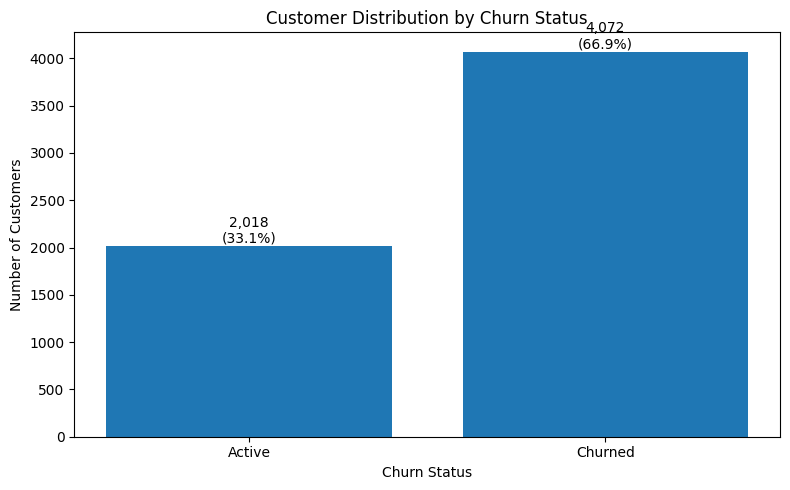

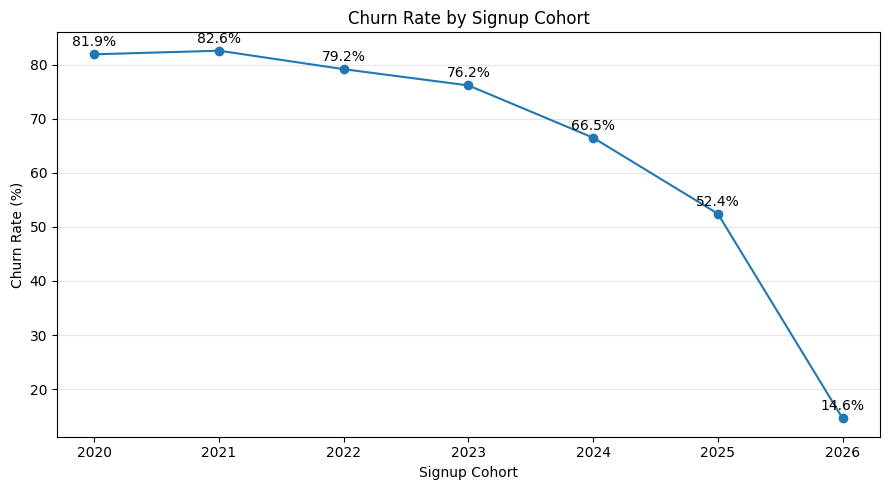


COHORT DATA USED FOR VISUALISATION
--------------------------------------------------------------------------------
   signup_cohort  customer_count  churn_rate_pct
0           2020             299           81.94
1           2021            1052           82.60
2           2022            1033           79.19
3           2023            1058           76.18
4           2024            1033           66.51
5           2025            1087           52.44
6           2026             528           14.58

VISUALISATION VALIDATION
--------------------------------------------------------------------------------
Overall churn population check: PASS
Cohort population check: PASS
Cohort percentage range check: PASS

CORE CHURN VISUALISATIONS: PASS


In [ ]:
# ============================================================
# CELL 24: CORE CHURN VISUALISATIONS
# ============================================================
#
# Purpose:
# Create the first presentation-quality visualisations for
# the churn analysis.
#
# Charts:
# 1. Overall customer distribution by churn status
# 2. Churn rate by signup cohort
#
# These visualisations support the EDA & Visualization section
# of the capstone rubric.
#
# Important:
# Cohort churn rates should be interpreted cautiously because
# newer cohorts have had less time to become inactive.
# ============================================================

print("=" * 80)
print("CORE CHURN VISUALISATIONS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Overall churn distribution
# ------------------------------------------------------------

churn_counts = (
    customers_rfm["churn_status"]
    .value_counts()
    .reindex(["Active", "Churned"])
)

churn_percentages = (
    churn_counts /
    churn_counts.sum() *
    100
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    churn_counts.index,
    churn_counts.values
)

plt.title(
    "Customer Distribution by Churn Status"
)

plt.xlabel(
    "Churn Status"
)

plt.ylabel(
    "Number of Customers"
)

# Add count and percentage labels above bars

for bar, count, percentage in zip(
    bars,
    churn_counts.values,
    churn_percentages.values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 2. Churn rate by signup cohort
# ------------------------------------------------------------

cohort_summary = (
    customers_rfm
    .groupby("signup_cohort")["churn_flag"]
    .agg(
        customer_count="count",
        churn_rate="mean"
    )
    .reset_index()
)

cohort_summary["churn_rate_pct"] = (
    cohort_summary["churn_rate"] * 100
)

plt.figure(figsize=(9, 5))

plt.plot(
    cohort_summary["signup_cohort"],
    cohort_summary["churn_rate_pct"],
    marker="o"
)

plt.title(
    "Churn Rate by Signup Cohort"
)

plt.xlabel(
    "Signup Cohort"
)

plt.ylabel(
    "Churn Rate (%)"
)

plt.xticks(
    cohort_summary["signup_cohort"]
)

plt.grid(
    axis="y",
    alpha=0.3
)

# Add percentage labels

for x, y in zip(
    cohort_summary["signup_cohort"],
    cohort_summary["churn_rate_pct"]
):

    plt.text(
        x,
        y + 1.5,
        f"{y:.1f}%",
        ha="center"
    )

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 3. Display cohort data behind the chart
# ------------------------------------------------------------

print("\nCOHORT DATA USED FOR VISUALISATION")
print("-" * 80)

print(
    cohort_summary[
        [
            "signup_cohort",
            "customer_count",
            "churn_rate_pct"
        ]
    ].round(2)
)

# ------------------------------------------------------------
# 4. Validation
# ------------------------------------------------------------

print("\nVISUALISATION VALIDATION")
print("-" * 80)

churn_population_check = (
    churn_counts.sum() == len(customers_rfm)
)

cohort_population_check = (
    cohort_summary["customer_count"].sum()
    == len(customers_rfm)
)

cohort_range_check = (
    cohort_summary["churn_rate_pct"]
    .between(0, 100)
    .all()
)

print(
    "Overall churn population check:",
    "PASS"
    if churn_population_check
    else "REVIEW REQUIRED"
)

print(
    "Cohort population check:",
    "PASS"
    if cohort_population_check
    else "REVIEW REQUIRED"
)

print(
    "Cohort percentage range check:",
    "PASS"
    if cohort_range_check
    else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if (
    churn_population_check
    and cohort_population_check
    and cohort_range_check
):
    print("CORE CHURN VISUALISATIONS: PASS")
else:
    print("CORE CHURN VISUALISATIONS: REVIEW REQUIRED")

print("=" * 80)

# Chart Insights & Business Interpretation

### Chart 1 — Overall customer churn distribution

The analysis classifies **4,072 of 6,090 customers (66.86%) as Churned**, compared with 2,018 Active customers (33.14%). This establishes churn as the central business problem: Meridian is dealing with a large inactive customer base, so retention and reactivation should be treated as a material customer-experience and revenue-priority issue.

### Chart 2 — Churn rate by signup cohort

Churn is highest among the older cohorts—**81.94% for 2020 and 82.60% for 2021**—and falls to 14.58% for the 2026 cohort. The pattern suggests that customer inactivity accumulates over time, but newer cohorts have had less time to reach the 180-day churn definition, so cohort differences should guide lifecycle thinking rather than be interpreted as causal effects.



RFM COMPARISON VISUALISATIONS

RFM VISUALISATION POPULATION
--------------------------------------------------------------------------------
Customers with qualifying completed-order history: 5643
Active customers: 2018
Churned customers: 3625


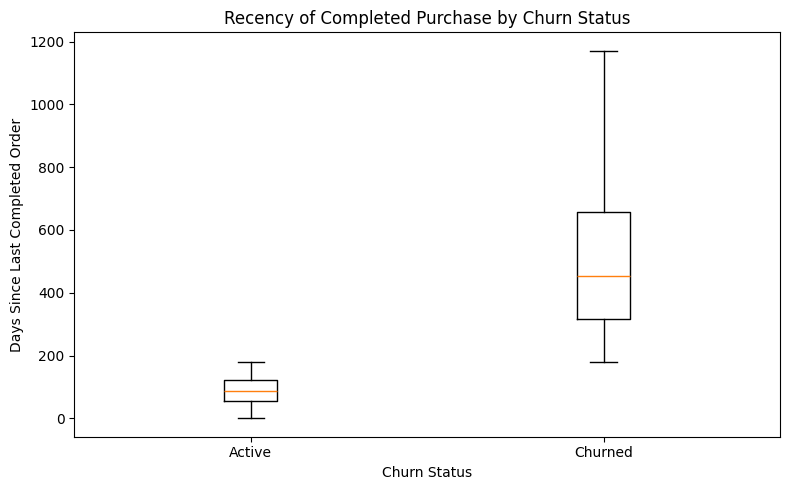

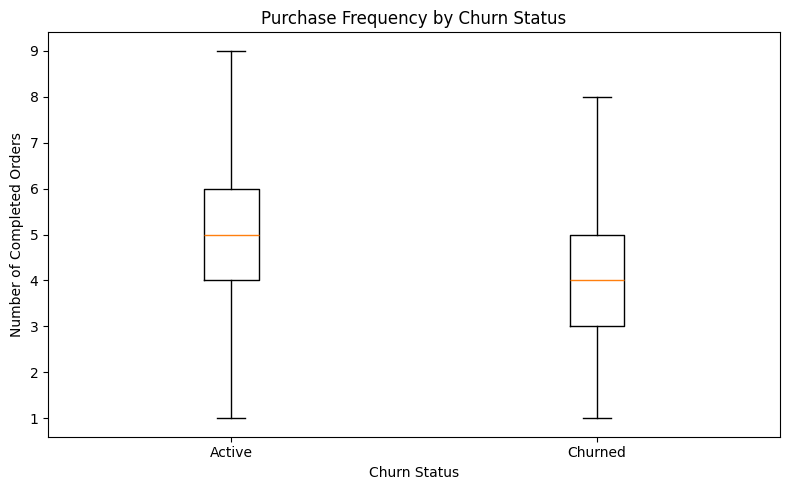

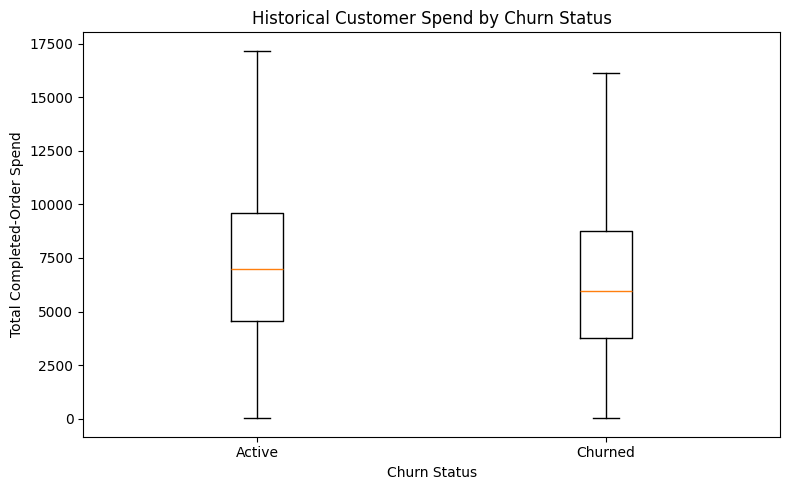


RFM MEDIAN COMPARISON
--------------------------------------------------------------------------------
              recency_days  frequency  monetary_total
churn_status                                         
Active                87.0        5.0         6981.66
Churned              454.0        4.0         5951.76

RFM VISUALISATION VALIDATION
--------------------------------------------------------------------------------
RFM population check: PASS
Active RFM count check: PASS
Churned RFM count check: PASS
Negative recency check: PASS

RFM COMPARISON VISUALISATIONS: PASS


In [ ]:
# ============================================================
# CELL 25: RFM COMPARISON VISUALISATIONS
# CORRECTED FINAL VERSION
# ============================================================
#
# Purpose:
# Compare purchasing behaviour between Active and Churned
# customers using the three core RFM dimensions:
#
#   R = Recency
#   F = Frequency
#   M = Monetary
#
# Important:
# These visualisations use only customers with a qualifying
# completed-order history and a valid completed-order date.
#
# Recency is closely related to the churn definition and must
# not be presented as an independent causal driver.
# ============================================================

print("=" * 80)
print("RFM COMPARISON VISUALISATIONS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Prepare the RFM visualisation population
# ------------------------------------------------------------

rfm_plot = customers_rfm[
    customers_rfm["recency_days"].notna()
].copy()

print("\nRFM VISUALISATION POPULATION")
print("-" * 80)

print(
    "Customers with qualifying completed-order history:",
    len(rfm_plot)
)

print(
    "Active customers:",
    (rfm_plot["churn_status"] == "Active").sum()
)

print(
    "Churned customers:",
    (rfm_plot["churn_status"] == "Churned").sum()
)

# ------------------------------------------------------------
# 2. Recency comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

recency_data = [
    rfm_plot.loc[
        rfm_plot["churn_status"] == "Active",
        "recency_days"
    ],
    rfm_plot.loc[
        rfm_plot["churn_status"] == "Churned",
        "recency_days"
    ]
]

plt.boxplot(
    recency_data,
    tick_labels=["Active", "Churned"],
    showfliers=False
)

plt.title("Recency of Completed Purchase by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Days Since Last Completed Order")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Frequency comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

frequency_data = [
    rfm_plot.loc[
        rfm_plot["churn_status"] == "Active",
        "frequency"
    ],
    rfm_plot.loc[
        rfm_plot["churn_status"] == "Churned",
        "frequency"
    ]
]

plt.boxplot(
    frequency_data,
    tick_labels=["Active", "Churned"],
    showfliers=False
)

plt.title("Purchase Frequency by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Number of Completed Orders")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Monetary comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

monetary_data = [
    rfm_plot.loc[
        rfm_plot["churn_status"] == "Active",
        "monetary_total"
    ],
    rfm_plot.loc[
        rfm_plot["churn_status"] == "Churned",
        "monetary_total"
    ]
]

plt.boxplot(
    monetary_data,
    tick_labels=["Active", "Churned"],
    showfliers=False
)

plt.title("Historical Customer Spend by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Total Completed-Order Spend")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Display medians used to interpret the charts
# ------------------------------------------------------------

rfm_median_comparison = (
    rfm_plot
    .groupby("churn_status")[
        ["recency_days", "frequency", "monetary_total"]
    ]
    .median()
    .reindex(["Active", "Churned"])
)

print("\nRFM MEDIAN COMPARISON")
print("-" * 80)
print(rfm_median_comparison.round(2))

# ------------------------------------------------------------
# 6. Validation
# ------------------------------------------------------------

print("\nRFM VISUALISATION VALIDATION")
print("-" * 80)

population_check = (
    len(rfm_plot)
    == customers_rfm["recency_days"].notna().sum()
)

active_rfm_check = (
    (rfm_plot["churn_status"] == "Active").sum() == 2018
)

churned_rfm_check = (
    (rfm_plot["churn_status"] == "Churned").sum() == 3625
)

negative_recency_check = (
    (rfm_plot["recency_days"] < 0).sum() == 0
)

print(
    "RFM population check:",
    "PASS" if population_check else "REVIEW REQUIRED"
)

print(
    "Active RFM count check:",
    "PASS" if active_rfm_check else "REVIEW REQUIRED"
)

print(
    "Churned RFM count check:",
    "PASS" if churned_rfm_check else "REVIEW REQUIRED"
)

print(
    "Negative recency check:",
    "PASS" if negative_recency_check else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if (
    population_check
    and active_rfm_check
    and churned_rfm_check
    and negative_recency_check
):
    print("RFM COMPARISON VISUALISATIONS: PASS")
else:
    print("RFM COMPARISON VISUALISATIONS: REVIEW REQUIRED")

print("=" * 80)

# Chart Insights & Business Interpretation

### Chart 3 — Recency of completed purchase by churn status

The median days since the last completed order is **87 days for Active customers versus 454 days for Churned customers**. This is the clearest descriptive separation between the groups, but recency is directly related to the 180-day churn definition; therefore, it should be interpreted as a status indicator and intervention signal, not as independent evidence of causation.

### Chart 4 — Purchase frequency by churn status

Active customers have a median of **5 completed orders**, compared with **4 for Churned customers**. The difference is directionally consistent with the idea that repeat purchasing is associated with stronger engagement, although the gap is modest and does not by itself establish that increasing order frequency will prevent churn.

### Chart 5 — Historical customer spend by churn status

Median historical completed-order spend is approximately **$6,981.66 for Active customers versus $5,426.34 for Churned customers**. Churn is therefore associated with lower historical customer value on average, supporting value-aware retention prioritisation rather than a one-size-fits-all campaign.



SUPPORT EXPERIENCE VISUALISATIONS

SUPPORT VISUALISATION POPULATION
--------------------------------------------------------------------------------
Customers with at least one support ticket: 3529
Active support users: 1163
Churned support users: 2366
Customers with recorded satisfaction: 3247
Customers with recorded resolution time: 3527


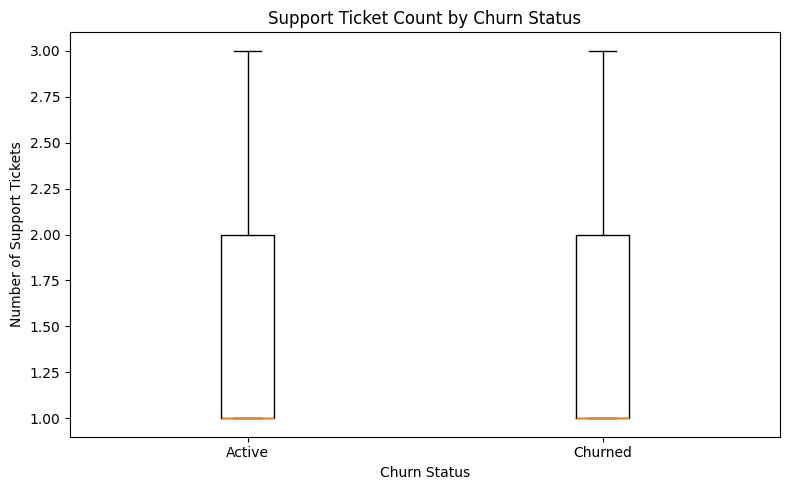

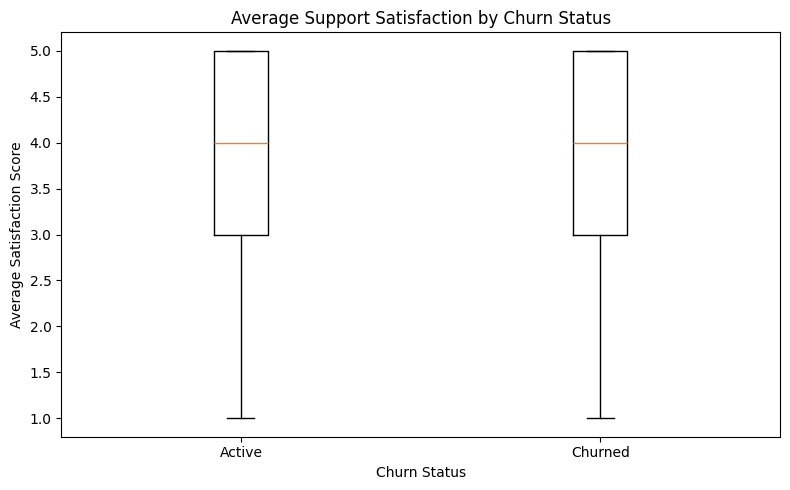

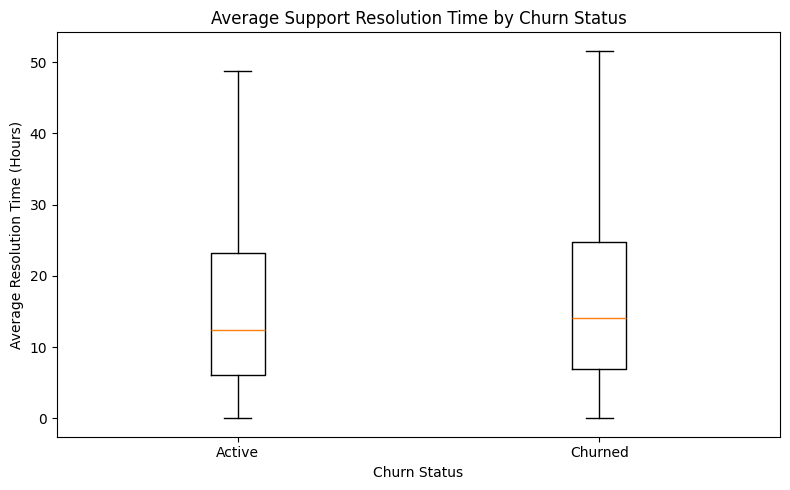


SUPPORT MEDIAN COMPARISON
--------------------------------------------------------------------------------
                                 Active  Churned
Support ticket count                1.0     1.00
Average satisfaction                4.0     4.00
Average resolution time (hours)    12.4    14.12

SUPPORT VISUALISATION VALIDATION
--------------------------------------------------------------------------------
Support-user population check: PASS
Active support-user count check: PASS
Churned support-user count check: PASS
Satisfaction coverage check: PASS
Resolution coverage check: PASS
Satisfaction range check: PASS
Resolution non-negative check: PASS

SUPPORT EXPERIENCE VISUALISATIONS: PASS


In [ ]:
# ============================================================
# CELL 26: SUPPORT EXPERIENCE VISUALISATIONS
# ============================================================
#
# Purpose:
# Visualise customer support experience by churn status.
#
# We focus on customers who actually contacted support so that
# customers with no support tickets are not incorrectly treated
# as having zero satisfaction or zero resolution time.
#
# Measures:
#   1. Support ticket count
#   2. Average satisfaction score
#   3. Average resolution time
#
# Important:
# Earlier statistical testing showed that support differences
# are generally small in practical terms. These charts are
# therefore descriptive and should not be interpreted as
# evidence that support experience causes churn.
# ============================================================

print("=" * 80)
print("SUPPORT EXPERIENCE VISUALISATIONS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Prepare support data up to the churn snapshot
# ------------------------------------------------------------

support_plot_base = support_tickets[
    support_tickets["ticket_date"].notna()
    & (support_tickets["ticket_date"] <= SNAPSHOT_DATE)
].copy()

# ------------------------------------------------------------
# 2. Aggregate support experience to customer level
# ------------------------------------------------------------

support_customer_plot = (
    support_plot_base
    .groupby("customer_id")
    .agg(
        support_ticket_count=("ticket_id", "nunique"),
        average_satisfaction=("satisfaction_score", "mean"),
        average_resolution_hours=("resolution_time_hours", "mean")
    )
    .reset_index()
)

# Add churn status to each support user.
support_customer_plot = support_customer_plot.merge(
    customers_rfm[
        ["customer_id", "churn_status"]
    ],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# ------------------------------------------------------------
# 3. Basic population information
# ------------------------------------------------------------

print("\nSUPPORT VISUALISATION POPULATION")
print("-" * 80)

print(
    "Customers with at least one support ticket:",
    len(support_customer_plot)
)

print(
    "Active support users:",
    (
        support_customer_plot["churn_status"] == "Active"
    ).sum()
)

print(
    "Churned support users:",
    (
        support_customer_plot["churn_status"] == "Churned"
    ).sum()
)

print(
    "Customers with recorded satisfaction:",
    support_customer_plot["average_satisfaction"].notna().sum()
)

print(
    "Customers with recorded resolution time:",
    support_customer_plot["average_resolution_hours"].notna().sum()
)

# ------------------------------------------------------------
# 4. Support ticket count comparison
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

ticket_data = [
    support_customer_plot.loc[
        support_customer_plot["churn_status"] == "Active",
        "support_ticket_count"
    ],
    support_customer_plot.loc[
        support_customer_plot["churn_status"] == "Churned",
        "support_ticket_count"
    ]
]

plt.boxplot(
    ticket_data,
    tick_labels=["Active", "Churned"],
    showfliers=False
)

plt.title("Support Ticket Count by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Number of Support Tickets")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Satisfaction comparison
# ------------------------------------------------------------

satisfaction_plot = support_customer_plot[
    support_customer_plot["average_satisfaction"].notna()
].copy()

plt.figure(figsize=(8, 5))

satisfaction_data = [
    satisfaction_plot.loc[
        satisfaction_plot["churn_status"] == "Active",
        "average_satisfaction"
    ],
    satisfaction_plot.loc[
        satisfaction_plot["churn_status"] == "Churned",
        "average_satisfaction"
    ]
]

plt.boxplot(
    satisfaction_data,
    tick_labels=["Active", "Churned"],
    showfliers=False
)

plt.title("Average Support Satisfaction by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Satisfaction Score")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Resolution time comparison
# ------------------------------------------------------------

resolution_plot = support_customer_plot[
    support_customer_plot["average_resolution_hours"].notna()
].copy()

plt.figure(figsize=(8, 5))

resolution_data = [
    resolution_plot.loc[
        resolution_plot["churn_status"] == "Active",
        "average_resolution_hours"
    ],
    resolution_plot.loc[
        resolution_plot["churn_status"] == "Churned",
        "average_resolution_hours"
    ]
]

plt.boxplot(
    resolution_data,
    tick_labels=["Active", "Churned"],
    showfliers=False
)

plt.title("Average Support Resolution Time by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Resolution Time (Hours)")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Display median comparisons
# ------------------------------------------------------------

support_median_comparison = pd.DataFrame({
    "Active": [
        support_customer_plot.loc[
            support_customer_plot["churn_status"] == "Active",
            "support_ticket_count"
        ].median(),

        satisfaction_plot.loc[
            satisfaction_plot["churn_status"] == "Active",
            "average_satisfaction"
        ].median(),

        resolution_plot.loc[
            resolution_plot["churn_status"] == "Active",
            "average_resolution_hours"
        ].median()
    ],

    "Churned": [
        support_customer_plot.loc[
            support_customer_plot["churn_status"] == "Churned",
            "support_ticket_count"
        ].median(),

        satisfaction_plot.loc[
            satisfaction_plot["churn_status"] == "Churned",
            "average_satisfaction"
        ].median(),

        resolution_plot.loc[
            resolution_plot["churn_status"] == "Churned",
            "average_resolution_hours"
        ].median()
    ]
}, index=[
    "Support ticket count",
    "Average satisfaction",
    "Average resolution time (hours)"
])

print("\nSUPPORT MEDIAN COMPARISON")
print("-" * 80)
print(support_median_comparison.round(2))

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

print("\nSUPPORT VISUALISATION VALIDATION")
print("-" * 80)

support_user_count_check = (
    len(support_customer_plot) == 3529
)

active_support_count_check = (
    (
        support_customer_plot["churn_status"] == "Active"
    ).sum() == 1163
)

churned_support_count_check = (
    (
        support_customer_plot["churn_status"] == "Churned"
    ).sum() == 2366
)

satisfaction_coverage_check = (
    satisfaction_plot["average_satisfaction"].notna().all()
)

resolution_coverage_check = (
    resolution_plot["average_resolution_hours"].notna().all()
)

satisfaction_range_check = (
    satisfaction_plot["average_satisfaction"]
    .between(1, 5)
    .all()
)

resolution_nonnegative_check = (
    resolution_plot["average_resolution_hours"] >= 0
).all()

print(
    "Support-user population check:",
    "PASS"
    if support_user_count_check
    else "REVIEW REQUIRED"
)

print(
    "Active support-user count check:",
    "PASS"
    if active_support_count_check
    else "REVIEW REQUIRED"
)

print(
    "Churned support-user count check:",
    "PASS"
    if churned_support_count_check
    else "REVIEW REQUIRED"
)

print(
    "Satisfaction coverage check:",
    "PASS"
    if satisfaction_coverage_check
    else "REVIEW REQUIRED"
)

print(
    "Resolution coverage check:",
    "PASS"
    if resolution_coverage_check
    else "REVIEW REQUIRED"
)

print(
    "Satisfaction range check:",
    "PASS"
    if satisfaction_range_check
    else "REVIEW REQUIRED"
)

print(
    "Resolution non-negative check:",
    "PASS"
    if resolution_nonnegative_check
    else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if (
    support_user_count_check
    and active_support_count_check
    and churned_support_count_check
    and satisfaction_coverage_check
    and resolution_coverage_check
    and satisfaction_range_check
    and resolution_nonnegative_check
):
    print("SUPPORT EXPERIENCE VISUALISATIONS: PASS")
else:
    print("SUPPORT EXPERIENCE VISUALISATIONS: REVIEW REQUIRED")

print("=" * 80)

# Chart Insights & Business Interpretation

### Chart 6 — Support ticket count by churn status

Customers who contacted support show very similar median ticket counts—**1 ticket for both Active and Churned support users**. This indicates that ticket volume alone is not a strong practical discriminator of churn and should not be used as a standalone retention trigger.

### Chart 7 — Average support satisfaction by churn status

Median support satisfaction is **4 for both Active and Churned support users**, with only a small statistical difference in the broader analysis. The business implication is that satisfaction appears relatively similar across the two groups, so Meridian should avoid assuming that low satisfaction is the primary explanation for the overall churn problem.

### Chart 8 — Average support resolution time by churn status

Churned support users have a median resolution time of about **14.12 hours versus 12.40 hours for Active support users**, a difference of roughly 1.72 hours. The difference is statistically detectable but practically small, so resolution time is better treated as a secondary service-quality signal than as a proven cause of churn.



CORRECTED CATEGORICAL CHURN VISUALISATIONS


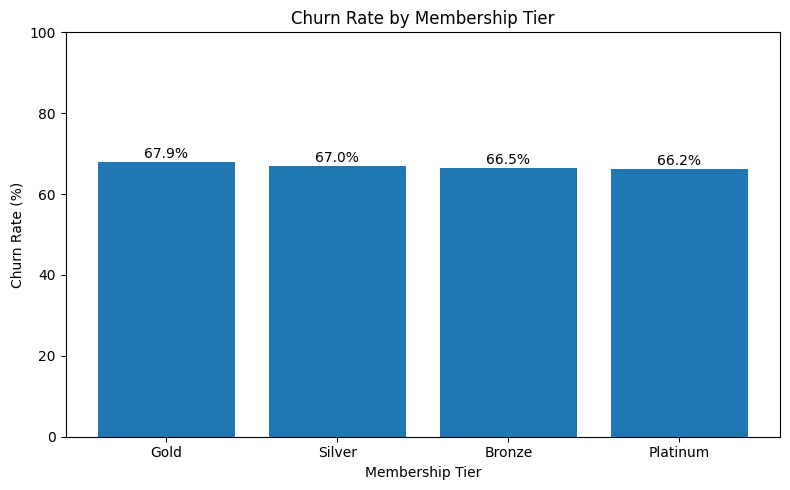

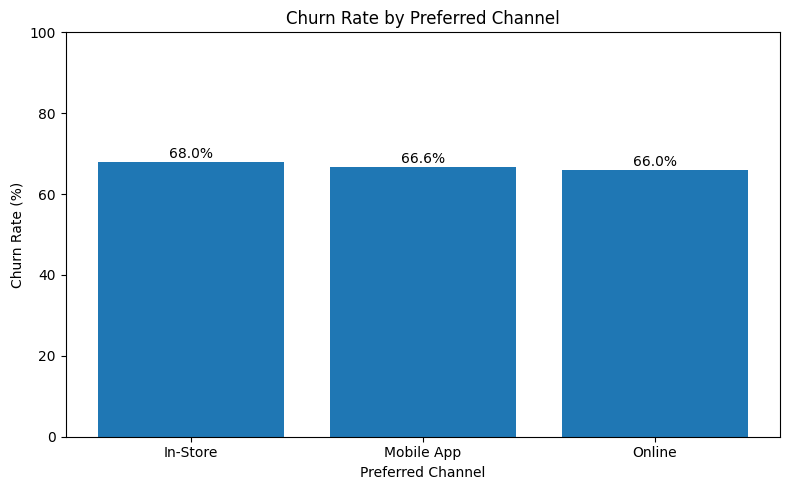

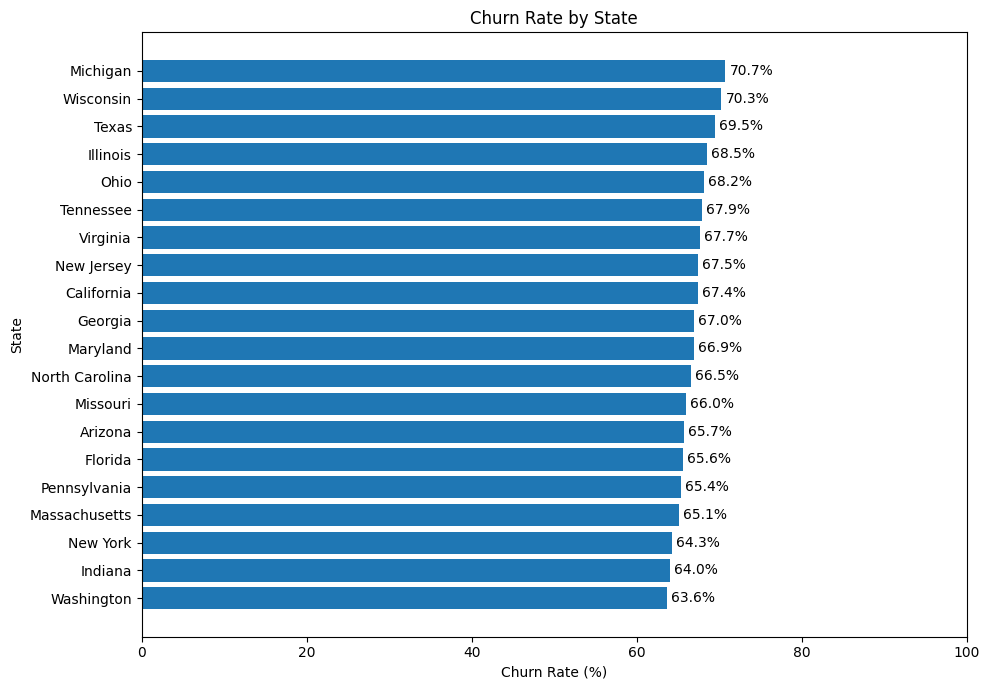

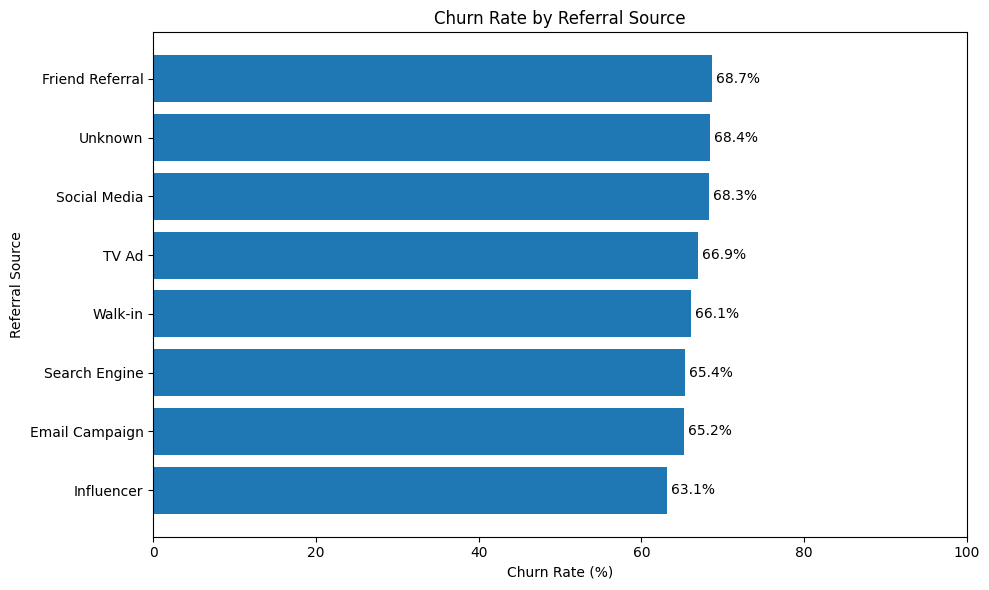


MEMBERSHIP TIER CHURN SUMMARY
--------------------------------------------------------------------------------
membership_tier  customer_count  active_count  churned_count  churn_rate_pct
         Bronze            2785           934           1851           66.46
           Gold            1126           361            765           67.94
       Platinum             411           139            272           66.18
         Silver            1768           584           1184           66.97

PREFERRED CHANNEL CHURN SUMMARY
--------------------------------------------------------------------------------
preferred_channel  customer_count  active_count  churned_count  churn_rate_pct
         In-Store            2041           654           1387           67.96
       Mobile App            2053           685           1368           66.63
           Online            1996           679           1317           65.98

STATE CHURN SUMMARY
----------------------------------------------------

In [ ]:
# ============================================================
# CELL 27B: CORRECTED CATEGORICAL CHURN VISUALISATIONS
# ============================================================
#
# Purpose:
# Visualise churn rates across:
#   1. Membership tier
#   2. Preferred channel
#   3. State
#   4. Referral source
#
# Correction:
# Missing referral-source values are explicitly labelled
# "Unknown" in an analysis copy.
#
# We do NOT modify customers_rfm itself.
#
# This ensures that all 6,090 customers remain represented
# in the referral-source analysis.
# ============================================================

print("=" * 80)
print("CORRECTED CATEGORICAL CHURN VISUALISATIONS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Create an analysis copy
# ------------------------------------------------------------

categorical_analysis = customers_rfm.copy()

# Preserve missing referral information by explicitly
# representing it as "Unknown" for this analysis only.
categorical_analysis["referral_source_analysis"] = (
    categorical_analysis["referral_source"]
    .fillna("Unknown")
)

# ------------------------------------------------------------
# 2. Helper function for calculating churn rates
# ------------------------------------------------------------

def calculate_churn_rate(dataframe, column):
    """
    Calculate customer count, active count, churned count,
    and churn rate for a categorical variable.
    """

    summary = (
        dataframe
        .groupby(column)["churn_flag"]
        .agg(
            customer_count="count",
            churned_count="sum"
        )
        .reset_index()
    )

    summary["active_count"] = (
        summary["customer_count"]
        - summary["churned_count"]
    )

    summary["churn_rate_pct"] = (
        summary["churned_count"]
        / summary["customer_count"]
        * 100
    )

    return summary


# ------------------------------------------------------------
# 3. Calculate summaries
# ------------------------------------------------------------

tier_summary = calculate_churn_rate(
    categorical_analysis,
    "membership_tier"
)

channel_summary = calculate_churn_rate(
    categorical_analysis,
    "preferred_channel"
)

state_summary = calculate_churn_rate(
    categorical_analysis,
    "state"
)

referral_summary = calculate_churn_rate(
    categorical_analysis,
    "referral_source_analysis"
)

# ------------------------------------------------------------
# 4. Membership tier
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

tier_plot = tier_summary.sort_values(
    "churn_rate_pct",
    ascending=False
)

bars = plt.bar(
    tier_plot["membership_tier"],
    tier_plot["churn_rate_pct"]
)

plt.title("Churn Rate by Membership Tier")
plt.xlabel("Membership Tier")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    tier_plot["churn_rate_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Preferred channel
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

channel_plot = channel_summary.sort_values(
    "churn_rate_pct",
    ascending=False
)

bars = plt.bar(
    channel_plot["preferred_channel"],
    channel_plot["churn_rate_pct"]
)

plt.title("Churn Rate by Preferred Channel")
plt.xlabel("Preferred Channel")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)

for bar, value in zip(
    bars,
    channel_plot["churn_rate_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. State
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

state_plot = state_summary.sort_values(
    "churn_rate_pct",
    ascending=True
)

bars = plt.barh(
    state_plot["state"],
    state_plot["churn_rate_pct"]
)

plt.title("Churn Rate by State")
plt.xlabel("Churn Rate (%)")
plt.ylabel("State")
plt.xlim(0, 100)

for bar, value in zip(
    bars,
    state_plot["churn_rate_pct"]
):
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Referral source
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

referral_plot = referral_summary.sort_values(
    "churn_rate_pct",
    ascending=True
)

bars = plt.barh(
    referral_plot["referral_source_analysis"],
    referral_plot["churn_rate_pct"]
)

plt.title("Churn Rate by Referral Source")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Referral Source")
plt.xlim(0, 100)

for bar, value in zip(
    bars,
    referral_plot["churn_rate_pct"]
):
    plt.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Display summary tables
# ------------------------------------------------------------

print("\nMEMBERSHIP TIER CHURN SUMMARY")
print("-" * 80)
print(
    tier_summary[
        [
            "membership_tier",
            "customer_count",
            "active_count",
            "churned_count",
            "churn_rate_pct"
        ]
    ]
    .sort_values("membership_tier")
    .round(2)
    .to_string(index=False)
)

print("\nPREFERRED CHANNEL CHURN SUMMARY")
print("-" * 80)
print(
    channel_summary[
        [
            "preferred_channel",
            "customer_count",
            "active_count",
            "churned_count",
            "churn_rate_pct"
        ]
    ]
    .sort_values("preferred_channel")
    .round(2)
    .to_string(index=False)
)

print("\nSTATE CHURN SUMMARY")
print("-" * 80)
print(
    state_summary[
        [
            "state",
            "customer_count",
            "active_count",
            "churned_count",
            "churn_rate_pct"
        ]
    ]
    .sort_values("churn_rate_pct", ascending=False)
    .round(2)
    .to_string(index=False)
)

print("\nREFERRAL SOURCE CHURN SUMMARY")
print("-" * 80)
print(
    referral_summary[
        [
            "referral_source_analysis",
            "customer_count",
            "active_count",
            "churned_count",
            "churn_rate_pct"
        ]
    ]
    .sort_values("churn_rate_pct", ascending=False)
    .round(2)
    .to_string(index=False)
)

# ------------------------------------------------------------
# 9. Validation
# ------------------------------------------------------------

print("\nCATEGORICAL VISUALISATION VALIDATION")
print("-" * 80)

tier_population_check = (
    tier_summary["customer_count"].sum()
    == len(customers_rfm)
)

channel_population_check = (
    channel_summary["customer_count"].sum()
    == len(customers_rfm)
)

state_population_check = (
    state_summary["customer_count"].sum()
    == len(customers_rfm)
)

referral_population_check = (
    referral_summary["customer_count"].sum()
    == len(customers_rfm)
)

tier_rate_check = (
    tier_summary["churn_rate_pct"].between(0, 100).all()
)

channel_rate_check = (
    channel_summary["churn_rate_pct"].between(0, 100).all()
)

state_rate_check = (
    state_summary["churn_rate_pct"].between(0, 100).all()
)

referral_rate_check = (
    referral_summary["churn_rate_pct"].between(0, 100).all()
)

unknown_referral_check = (
    referral_summary["referral_source_analysis"]
    .eq("Unknown")
    .sum() == 1
)

unknown_customer_count_check = (
    referral_summary.loc[
        referral_summary["referral_source_analysis"] == "Unknown",
        "customer_count"
    ].iloc[0] == 1705
)

print(
    "Membership tier population check:",
    "PASS" if tier_population_check else "REVIEW REQUIRED"
)

print(
    "Preferred channel population check:",
    "PASS" if channel_population_check else "REVIEW REQUIRED"
)

print(
    "State population check:",
    "PASS" if state_population_check else "REVIEW REQUIRED"
)

print(
    "Referral source population check:",
    "PASS" if referral_population_check else "REVIEW REQUIRED"
)

print(
    "Membership tier rate range check:",
    "PASS" if tier_rate_check else "REVIEW REQUIRED"
)

print(
    "Preferred channel rate range check:",
    "PASS" if channel_rate_check else "REVIEW REQUIRED"
)

print(
    "State rate range check:",
    "PASS" if state_rate_check else "REVIEW REQUIRED"
)

print(
    "Referral source rate range check:",
    "PASS" if referral_rate_check else "REVIEW REQUIRED"
)

print(
    "Unknown referral category check:",
    "PASS" if unknown_referral_check else "REVIEW REQUIRED"
)

print(
    "Unknown referral customer count check:",
    "PASS"
    if unknown_customer_count_check
    else "REVIEW REQUIRED"
)

print("\n" + "=" * 80)

if (
    tier_population_check
    and channel_population_check
    and state_population_check
    and referral_population_check
    and tier_rate_check
    and channel_rate_check
    and state_rate_check
    and referral_rate_check
    and unknown_referral_check
    and unknown_customer_count_check
):
    print("CATEGORICAL CHURN VISUALISATIONS: PASS")
else:
    print("CATEGORICAL CHURN VISUALISATIONS: REVIEW REQUIRED")

print("=" * 80)

# Chart Insights & Business Interpretation

### Chart 9 — Churn rate by membership tier

Churn rates are tightly clustered across tiers: **66.18% for Platinum, 66.46% Bronze, 66.97% Silver and 67.94% Gold**. The narrow spread and non-significant association indicate that membership tier alone does not provide a strong basis for prioritising retention resources.

### Chart 10 — Churn rate by preferred channel

Churn is similarly high across channels: **67.96% In-Store, 66.63% Mobile App and 65.98% Online**. The small range suggests that the problem is broad-based rather than confined to a single purchasing channel, supporting an omnichannel retention strategy.

### Chart 11 — Churn rate by state

State-level churn ranges from **63.64% in Washington to 70.75% in Michigan**, a 7.11-percentage-point spread. These differences may help Meridian investigate local customer behaviour, but the statistical analysis did not identify a meaningful overall state association, so geography should not be treated as causal.

### Chart 12 — Churn rate by referral source

Referral-source churn ranges from **63.12% for Influencer-acquired customers to 68.73% for Friend Referral**, while 1,705 customers have unknown referral information and show a 68.39% churn rate. Because the categorical association is not statistically meaningful and referral data are partly missing, referral source is more useful for monitoring acquisition quality than for direct churn intervention.



CUSTOMER PURCHASE BEHAVIOUR DISTRIBUTION
Total customers analysed: 6,090
Customers with frequency = 0: 447
Percentage with frequency = 0: 7.34%
Customers with monetary total = 0: 447
Percentage with monetary total = 0: 7.34%

--- Purchase Frequency Summary ---
count    6090.000000
mean        4.117898
std         2.144606
min         0.000000
25%         3.000000
50%         4.000000
75%         6.000000
max        14.000000
Name: frequency, dtype: float64

--- Monetary Total Summary ---
count     6090.000000
mean      6336.256123
std       4087.126474
min          0.000000
25%       3377.150000
50%       5942.240000
75%       8811.880000
max      35395.370000
Name: monetary_total, dtype: float64


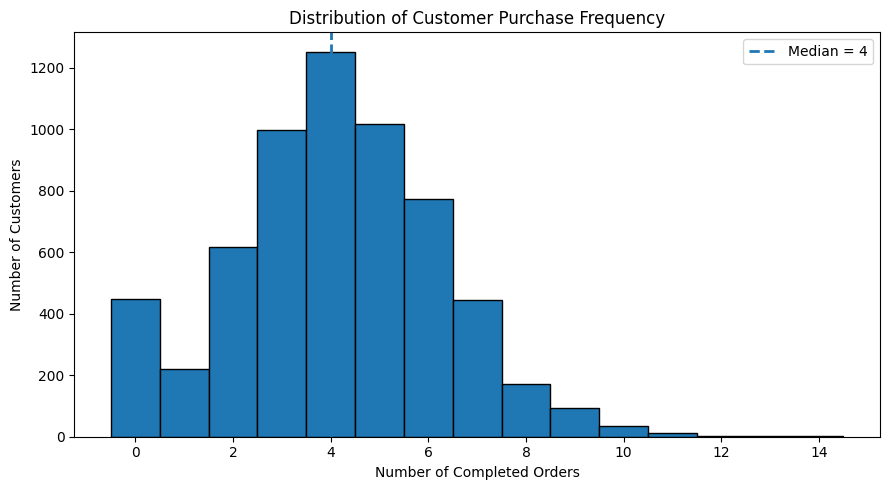

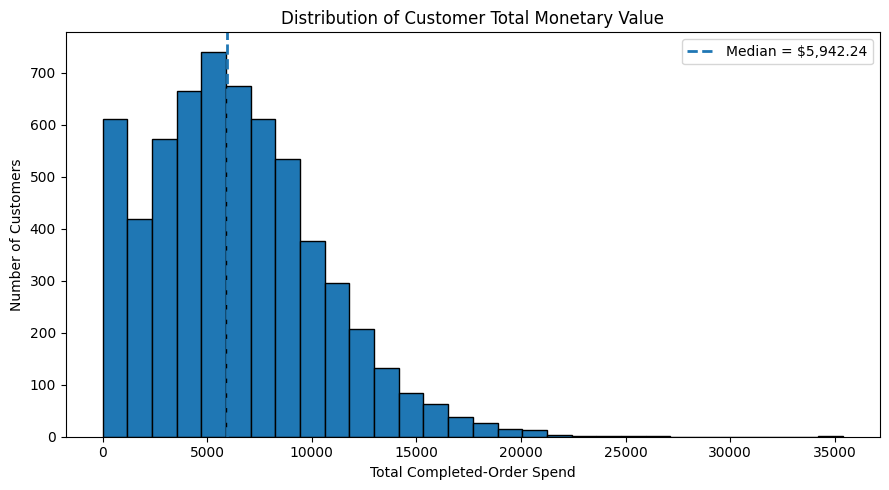


--- VALIDATION ---
Customer population matches customers_rfm: PASS
Frequency non-negative: PASS
Monetary values non-negative: PASS
Zero-frequency / zero-monetary reconciliation: PASS

Cell 28: Customer Purchase Behaviour Analysis COMPLETE.


In [ ]:
# ============================================================
# CELL 28 — CUSTOMER PURCHASE BEHAVIOUR DISTRIBUTIONS
# ============================================================
# Purpose:
# Examine how frequently customers purchase and how much they
# have spent historically up to the churn snapshot date.
#
# Why this matters:
# - Helps us understand the overall customer purchasing pattern.
# - Reveals skewness, concentration and unusual values.
# - Supports the EDA & Visualization marks in the rubric.
# - Provides evidence for later business recommendations.
#
# Important:
# We use the RFM values already calculated in customers_rfm.
# Frequency = number of qualifying completed orders.
# Monetary Total = total completed-order spend up to 2026-07-01.
# Customers without qualifying completed-order history have
# Frequency = 0 and Monetary Total = 0.
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Make a copy for this analysis
# ------------------------------------------------------------
purchase_behavior = customers_rfm[
    ["customer_id", "frequency", "monetary_total"]
].copy()

# ------------------------------------------------------------
# 2. Basic validation
# ------------------------------------------------------------
purchase_population = len(purchase_behavior)

frequency_nonnegative = (purchase_behavior["frequency"] >= 0).all()
monetary_nonnegative = (purchase_behavior["monetary_total"] >= 0).all()

zero_frequency_count = (
    purchase_behavior["frequency"] == 0
).sum()

zero_monetary_count = (
    purchase_behavior["monetary_total"] == 0
).sum()

# ------------------------------------------------------------
# 3. Summary statistics
# ------------------------------------------------------------
frequency_summary = purchase_behavior["frequency"].describe()

monetary_summary = purchase_behavior["monetary_total"].describe()

print("CUSTOMER PURCHASE BEHAVIOUR DISTRIBUTION")
print("=" * 60)

print(f"Total customers analysed: {purchase_population:,}")
print(f"Customers with frequency = 0: {zero_frequency_count:,}")
print(
    f"Percentage with frequency = 0: "
    f"{zero_frequency_count / purchase_population * 100:.2f}%"
)

print(f"Customers with monetary total = 0: {zero_monetary_count:,}")
print(
    f"Percentage with monetary total = 0: "
    f"{zero_monetary_count / purchase_population * 100:.2f}%"
)

print("\n--- Purchase Frequency Summary ---")
print(frequency_summary)

print("\n--- Monetary Total Summary ---")
print(monetary_summary)

# ------------------------------------------------------------
# 4. Frequency distribution
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))

# Integer-centred bins make each order count visible.
frequency_bins = np.arange(
    purchase_behavior["frequency"].min() - 0.5,
    purchase_behavior["frequency"].max() + 1.5,
    1
)

plt.hist(
    purchase_behavior["frequency"],
    bins=frequency_bins,
    edgecolor="black"
)

plt.axvline(
    purchase_behavior["frequency"].median(),
    linestyle="--",
    linewidth=2,
    label=f"Median = {purchase_behavior['frequency'].median():.0f}"
)

plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Number of Completed Orders")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Monetary-value distribution
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))

plt.hist(
    purchase_behavior["monetary_total"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    purchase_behavior["monetary_total"].median(),
    linestyle="--",
    linewidth=2,
    label=(
        f"Median = "
        f"${purchase_behavior['monetary_total'].median():,.2f}"
    )
)

plt.title("Distribution of Customer Total Monetary Value")
plt.xlabel("Total Completed-Order Spend")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. Validation checks
# ------------------------------------------------------------
assert purchase_population == len(customers_rfm), \
    "Purchase population does not match customers_rfm."

assert frequency_nonnegative, \
    "Negative purchase frequencies detected."

assert monetary_nonnegative, \
    "Negative monetary values detected."

assert zero_frequency_count == zero_monetary_count, \
    "Frequency and monetary zero counts do not reconcile."

print("\n--- VALIDATION ---")
print(
    "Customer population matches customers_rfm: PASS"
    if purchase_population == len(customers_rfm)
    else "Customer population matches customers_rfm: FAIL"
)

print(
    "Frequency non-negative: PASS"
    if frequency_nonnegative
    else "Frequency non-negative: FAIL"
)

print(
    "Monetary values non-negative: PASS"
    if monetary_nonnegative
    else "Monetary values non-negative: FAIL"
)

print(
    "Zero-frequency / zero-monetary reconciliation: PASS"
    if zero_frequency_count == zero_monetary_count
    else "Zero-frequency / zero-monetary reconciliation: FAIL"
)

print("\nCell 28: Customer Purchase Behaviour Analysis COMPLETE.")

# Chart Insights & Business Interpretation

### Chart 13 — Distribution of customer purchase frequency

Across all 6,090 customers, the median is **4 completed orders**, while **447 customers (7.34%) have zero completed orders**. The distribution shows meaningful variation in engagement, reinforcing the need for lifecycle segmentation and early reactivation of customers who have not yet developed repeat-purchase behaviour.

### Chart 14 — Distribution of customer total monetary value

Historical completed-order value has a median of **$5,942.24**, with a maximum of **$35,395.37** and 447 customers at zero value. The wide spread indicates that customer value is heterogeneous; retention decisions should therefore consider both churn likelihood and customer value.



In [ ]:
# ============================================================
# CELL 29 — INTERACTIVE PURCHASE FREQUENCY VS MONETARY VALUE
# ============================================================
# Purpose:
# Examine the relationship between:
#   1. Purchase frequency
#   2. Total monetary value
#   3. Churn status
#
# This is a multivariate EDA analysis because we are examining
# customer purchasing behaviour together with churn status.
#
# We will also calculate Spearman correlation because purchase
# frequency and monetary value may not have a perfectly linear
# relationship.
# ============================================================

import plotly.express as px

# ------------------------------------------------------------
# 1. Prepare analysis dataset
# ------------------------------------------------------------
purchase_relationship = customers_rfm[
    [
        "customer_id",
        "churn_status",
        "frequency",
        "monetary_total"
    ]
].copy()

# ------------------------------------------------------------
# 2. Validate the population
# ------------------------------------------------------------
relationship_population = len(purchase_relationship)

frequency_missing = purchase_relationship["frequency"].isna().sum()
monetary_missing = purchase_relationship["monetary_total"].isna().sum()
churn_missing = purchase_relationship["churn_status"].isna().sum()

# ------------------------------------------------------------
# 3. Calculate Spearman correlation
# ------------------------------------------------------------
# Spearman correlation measures whether customers with higher
# purchase frequency also tend to have higher monetary value.
#
# It is appropriate here because the distributions are skewed
# and the relationship does not have to be perfectly linear.

spearman_correlation = purchase_relationship[
    ["frequency", "monetary_total"]
].corr(method="spearman").iloc[0, 1]

# ------------------------------------------------------------
# 4. Print analysis summary
# ------------------------------------------------------------
print("PURCHASE FREQUENCY VS MONETARY VALUE")
print("=" * 60)

print(f"Customers analysed: {relationship_population:,}")
print(f"Missing frequency values: {frequency_missing:,}")
print(f"Missing monetary values: {monetary_missing:,}")
print(f"Missing churn status values: {churn_missing:,}")

print(
    f"\nSpearman correlation between purchase frequency "
    f"and monetary total: {spearman_correlation:.4f}"
)

# ------------------------------------------------------------
# 5. Display churn-status counts
# ------------------------------------------------------------
print("\nCustomers by churn status:")
print(
    purchase_relationship["churn_status"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 6. Create interactive Plotly scatter plot
# ------------------------------------------------------------
fig = px.scatter(
    purchase_relationship,
    x="frequency",
    y="monetary_total",
    color="churn_status",
    hover_name="customer_id",
    hover_data={
        "frequency": True,
        "monetary_total": ":,.2f",
        "churn_status": True
    },
    title="Customer Purchase Frequency vs Total Monetary Value",
    labels={
        "frequency": "Number of Completed Orders",
        "monetary_total": "Total Completed-Order Spend",
        "churn_status": "Customer Status"
    },
    opacity=0.65,
    render_mode="webgl"
)

fig.update_layout(
    xaxis_title="Number of Completed Orders",
    yaxis_title="Total Completed-Order Spend",
    legend_title="Customer Status"
)

fig.show()

# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------
assert relationship_population == len(customers_rfm), \
    "Population does not match customers_rfm."

assert frequency_missing == 0, \
    "Missing frequency values detected."

assert monetary_missing == 0, \
    "Missing monetary values detected."

assert churn_missing == 0, \
    "Missing churn status values detected."

print("\n--- VALIDATION ---")

print(
    "Population matches customers_rfm: PASS"
    if relationship_population == len(customers_rfm)
    else "Population matches customers_rfm: FAIL"
)

print(
    "Frequency completeness: PASS"
    if frequency_missing == 0
    else "Frequency completeness: FAIL"
)

print(
    "Monetary completeness: PASS"
    if monetary_missing == 0
    else "Monetary completeness: FAIL"
)

print(
    "Churn status completeness: PASS"
    if churn_missing == 0
    else "Churn status completeness: FAIL"
)

print("\nCell 29: Interactive Purchase Relationship Analysis COMPLETE.")

PURCHASE FREQUENCY VS MONETARY VALUE
Customers analysed: 6,090
Missing frequency values: 0
Missing monetary values: 0
Missing churn status values: 0

Spearman correlation between purchase frequency and monetary total: 0.8110

Customers by churn status:
churn_status
Active     2018
Churned    4072
Name: count, dtype: int64



--- VALIDATION ---
Population matches customers_rfm: PASS
Frequency completeness: PASS
Monetary completeness: PASS
Churn status completeness: PASS

Cell 29: Interactive Purchase Relationship Analysis COMPLETE.


# Chart Insights & Business Interpretation

### Chart 15 — Interactive purchase frequency versus monetary value

The interactive relationship shows a strong positive Spearman correlation of **0.811** between purchase frequency and historical monetary value. In business terms, customers who purchase more frequently tend to accumulate substantially greater historical value, making repeat-purchase engagement an important retention lever; however, this is an association, not proof that frequency causes value or vice versa.



In [ ]:
# ============================================================
# CELL 30 — INTERACTIVE SUPPORT RESOLUTION TIME BY CHURN STATUS
# ============================================================
# Purpose:
# Examine whether support resolution time differs between
# Active and Churned customers.
#
# This is a business-focused multivariate EDA analysis because
# we are connecting:
#   - Support experience
#   - Resolution time
#   - Customer churn status
#
# We use a box plot because resolution time is continuous and
# may contain extreme values. A box plot allows us to compare
# the median, spread and potential extreme observations.
# ============================================================

import plotly.express as px

# ------------------------------------------------------------
# 1. Prepare customer-level support resolution data
# ------------------------------------------------------------

support_analysis = support_tickets[
    [
        "customer_id",
        "resolution_time_hours"
    ]
].copy()

# Keep only valid resolution times.
# Missing resolution times are not imputed because they represent
# unavailable historical information.
support_analysis = support_analysis[
    support_analysis["resolution_time_hours"].notna()
].copy()

# ------------------------------------------------------------
# 2. Aggregate resolution time to customer level
# ------------------------------------------------------------
# A customer may have multiple support tickets.
# We use the mean resolution time per customer so that customers
# with many tickets do not receive disproportionate weight.

customer_resolution = (
    support_analysis
    .groupby("customer_id", as_index=False)
    .agg(
        average_resolution_hours=(
            "resolution_time_hours",
            "mean"
        )
    )
)

# ------------------------------------------------------------
# 3. Add churn status
# ------------------------------------------------------------
customer_resolution = customer_resolution.merge(
    customers_rfm[
        ["customer_id", "churn_status"]
    ],
    on="customer_id",
    how="left"
)

# ------------------------------------------------------------
# 4. Validation checks
# ------------------------------------------------------------

resolution_population = len(customer_resolution)

missing_churn = (
    customer_resolution["churn_status"].isna().sum()
)

negative_resolution = (
    customer_resolution["average_resolution_hours"] < 0
).sum()

status_counts = (
    customer_resolution["churn_status"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# 5. Calculate descriptive statistics by churn status
# ------------------------------------------------------------

resolution_summary = (
    customer_resolution
    .groupby("churn_status")["average_resolution_hours"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        minimum="min",
        maximum="max"
    )
)

print("SUPPORT RESOLUTION TIME VS CHURN STATUS")
print("=" * 60)

print(
    f"Customers with recorded resolution time: "
    f"{resolution_population:,}"
)

print("\nCustomers by churn status:")
print(status_counts)

print("\nResolution-time summary by churn status:")
print(resolution_summary)

# ------------------------------------------------------------
# 6. Calculate median difference
# ------------------------------------------------------------

active_median = (
    customer_resolution.loc[
        customer_resolution["churn_status"] == "Active",
        "average_resolution_hours"
    ].median()
)

churned_median = (
    customer_resolution.loc[
        customer_resolution["churn_status"] == "Churned",
        "average_resolution_hours"
    ].median()
)

median_difference = churned_median - active_median

print("\nMedian comparison:")
print(f"Active customers: {active_median:.2f} hours")
print(f"Churned customers: {churned_median:.2f} hours")
print(f"Difference: {median_difference:+.2f} hours")

# ------------------------------------------------------------
# 7. Interactive Plotly box plot
# ------------------------------------------------------------

fig = px.box(
    customer_resolution,
    x="churn_status",
    y="average_resolution_hours",
    color="churn_status",
    points="outliers",
    hover_data={
        "customer_id": True,
        "average_resolution_hours": ":.2f",
        "churn_status": True
    },
    title="Customer Support Resolution Time by Churn Status",
    labels={
        "churn_status": "Customer Status",
        "average_resolution_hours":
            "Average Resolution Time (Hours)"
    }
)

fig.update_layout(
    xaxis_title="Customer Status",
    yaxis_title="Average Resolution Time (Hours)",
    legend_title="Customer Status"
)

fig.show()

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

assert resolution_population > 0, \
    "No customers with valid resolution time found."

assert missing_churn == 0, \
    "Some support customers have missing churn status."

assert negative_resolution == 0, \
    "Negative average resolution times detected."

print("\n--- VALIDATION ---")

print(
    "Resolution-time customer population created: PASS"
    if resolution_population > 0
    else "Resolution-time customer population created: FAIL"
)

print(
    "Churn status completeness: PASS"
    if missing_churn == 0
    else "Churn status completeness: FAIL"
)

print(
    "No negative resolution times: PASS"
    if negative_resolution == 0
    else "No negative resolution times: FAIL"
)

print(
    "\nCell 30: Interactive Support Resolution Analysis COMPLETE."
)

SUPPORT RESOLUTION TIME VS CHURN STATUS
Customers with recorded resolution time: 3,527

Customers by churn status:
churn_status
Active     1163
Churned    2364
Name: count, dtype: int64

Resolution-time summary by churn status:
              count       mean  median        std  minimum  maximum
churn_status                                                       
Active         1163  17.320079  12.400  20.300097      0.0   422.25
Churned        2364  18.794113  14.125  22.345517      0.0   682.00

Median comparison:
Active customers: 12.40 hours
Churned customers: 14.12 hours
Difference: +1.72 hours



--- VALIDATION ---
Resolution-time customer population created: PASS
Churn status completeness: PASS
No negative resolution times: PASS

Cell 30: Interactive Support Resolution Analysis COMPLETE.


# Chart Insights & Business Interpretation

### Chart 16 — Interactive support resolution time by churn status

Among customers with support records, Churned customers show a somewhat longer resolution-time distribution, with a median around **14.12 hours versus 12.40 hours for Active customers**. The difference is useful as a service-quality diagnostic, but its small effect size means Meridian should not expect support-resolution changes alone to solve the churn problem.



HISTORICAL CUSTOMER VALUE BY CHURN STATUS
churn_status  customers  total_historical_value  average_historical_value  median_historical_value  share_of_total_value_pct
      Active       2018             14982653.53               7424.506209                 6981.655                 38.827437
     Churned       4072             23605146.26               5796.941616                 5426.335                 61.172563

Business-value summary:
Historical value associated with Churned customers: $23,605,146.26
Historical value associated with Active customers: $14,982,653.53
Churned customers' share of total historical value: 61.17%


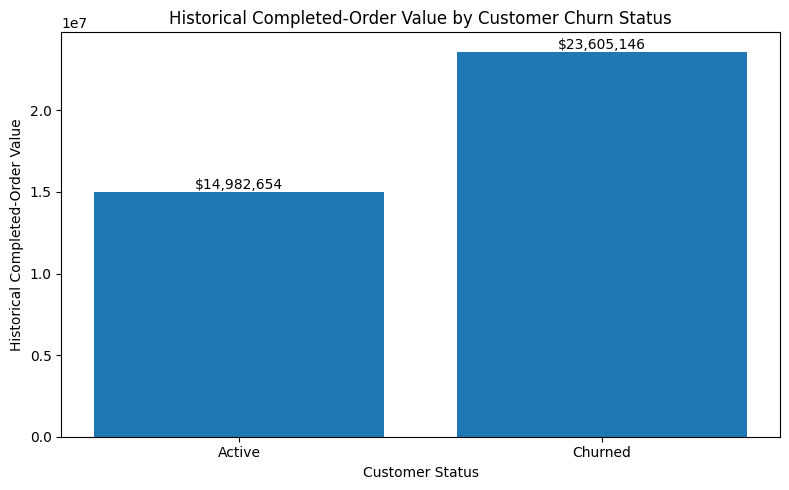


--- VALIDATION ---
Active and Churned groups present: PASS
Customer population reconciliation: PASS
Historical-value shares sum to 100%: PASS
No negative historical monetary values: PASS

Cell 31: Historical Customer Value Analysis COMPLETE.


In [ ]:
# ============================================================
# CELL 31 — HISTORICAL CUSTOMER VALUE BY CHURN STATUS
# ============================================================
# Purpose:
# Quantify the historical completed-order monetary value
# associated with Active and Churned customers.
#
# Business relevance:
# This helps translate the churn analysis into financial
# business impact.
#
# Important methodological caution:
# monetary_total represents HISTORICAL completed-order spend
# up to the churn snapshot date. It is NOT automatically
# equivalent to future revenue at risk.
# ============================================================

# ------------------------------------------------------------
# 1. Prepare analysis dataset
# ------------------------------------------------------------

value_by_churn = customers_rfm[
    [
        "customer_id",
        "churn_status",
        "monetary_total"
    ]
].copy()

# ------------------------------------------------------------
# 2. Aggregate historical monetary value
# ------------------------------------------------------------

value_summary = (
    value_by_churn
    .groupby("churn_status")
    .agg(
        customers=("customer_id", "count"),
        total_historical_value=("monetary_total", "sum"),
        average_historical_value=("monetary_total", "mean"),
        median_historical_value=("monetary_total", "median")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 3. Calculate percentage of total historical value
# ------------------------------------------------------------

total_historical_value = (
    value_summary["total_historical_value"].sum()
)

value_summary["share_of_total_value_pct"] = (
    value_summary["total_historical_value"]
    / total_historical_value
    * 100
)

# ------------------------------------------------------------
# 4. Print results
# ------------------------------------------------------------

print("HISTORICAL CUSTOMER VALUE BY CHURN STATUS")
print("=" * 65)

print(value_summary.to_string(index=False))

# ------------------------------------------------------------
# 5. Extract churned-customer values
# ------------------------------------------------------------

churned_value = value_summary.loc[
    value_summary["churn_status"] == "Churned",
    "total_historical_value"
].iloc[0]

active_value = value_summary.loc[
    value_summary["churn_status"] == "Active",
    "total_historical_value"
].iloc[0]

churned_share = value_summary.loc[
    value_summary["churn_status"] == "Churned",
    "share_of_total_value_pct"
].iloc[0]

print("\nBusiness-value summary:")
print(
    f"Historical value associated with Churned customers: "
    f"${churned_value:,.2f}"
)

print(
    f"Historical value associated with Active customers: "
    f"${active_value:,.2f}"
)

print(
    f"Churned customers' share of total historical value: "
    f"{churned_share:.2f}%"
)

# ------------------------------------------------------------
# 6. Visualise historical value by churn status
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    value_summary["churn_status"],
    value_summary["total_historical_value"]
)

plt.title(
    "Historical Completed-Order Value by Customer Churn Status"
)

plt.xlabel("Customer Status")
plt.ylabel("Historical Completed-Order Value")

# Add value labels above the bars
for index, value in enumerate(
    value_summary["total_historical_value"]
):
    plt.text(
        index,
        value,
        f"${value:,.0f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. Validation
# ------------------------------------------------------------

assert len(value_summary) == 2, \
    "Expected exactly two churn-status groups."

assert (
    value_summary["customers"].sum()
    == len(customers_rfm)
), "Customer population does not reconcile."

assert (
    abs(
        value_summary["share_of_total_value_pct"].sum()
        - 100
    ) < 0.0001
), "Historical-value shares do not sum to 100%."

assert (
    value_summary["total_historical_value"] >= 0
).all(), "Negative historical monetary value detected."

print("\n--- VALIDATION ---")

print(
    "Active and Churned groups present: PASS"
    if len(value_summary) == 2
    else "Active and Churned groups present: FAIL"
)

print(
    "Customer population reconciliation: PASS"
    if value_summary["customers"].sum() == len(customers_rfm)
    else "Customer population reconciliation: FAIL"
)

print(
    "Historical-value shares sum to 100%: PASS"
    if abs(
        value_summary["share_of_total_value_pct"].sum() - 100
    ) < 0.0001
    else "Historical-value shares sum to 100%: FAIL"
)

print(
    "No negative historical monetary values: PASS"
    if (value_summary["total_historical_value"] >= 0).all()
    else "No negative historical monetary values: FAIL"
)

print(
    "\nCell 31: Historical Customer Value Analysis COMPLETE."
)

# Chart Insights & Business Interpretation

### Chart 17 — Historical completed-order value by churn status

Churned customers account for **$23.61 million, or 61.17% of total historical completed-order value**, compared with $14.98 million for Active customers. This is an important financial-priority signal: a large share of Meridian's historical customer value is attached to customers who are now inactive, although this figure is **not the same as future revenue at risk**.



CHURN RATE BY PURCHASE-FREQUENCY GROUP
frequency_group  customers  active_customers  churned_customers  churn_rate_pct
       0 orders        447                 0                447      100.000000
     1–2 orders        837               203                634       75.746714
     3–4 orders       2251               747               1504       66.814749
     5–6 orders       1793               718               1075       59.955382
      7+ orders        762               350                412       54.068241

Churn-rate range across frequency groups:
45.93 percentage points


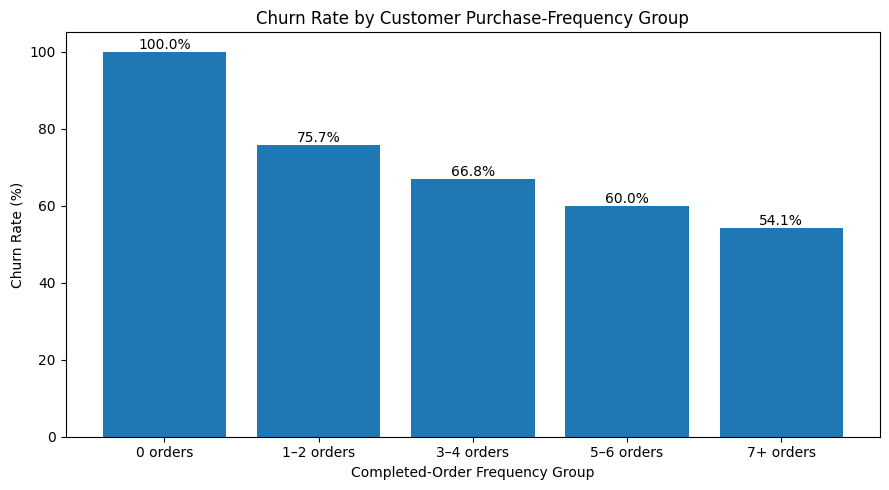


--- VALIDATION ---
Frequency-group population reconciliation: PASS
Churned-customer reconciliation: PASS
Active-customer reconciliation: PASS
Churn rates within valid range: PASS

Cell 32: Purchase-Frequency Churn Analysis COMPLETE.


In [ ]:
# ============================================================
# CELL 32 — CHURN RATE BY PURCHASE-FREQUENCY GROUP
# ============================================================
# Purpose:
# Examine how churn varies across customer purchase-frequency
# groups.
#
# Business question:
# "Is customer churn concentrated among customers with fewer
# completed orders?"
#
# Important methodological note:
# Frequency is calculated from completed orders up to the
# churn snapshot date. Therefore, this analysis is descriptive.
# It should NOT be interpreted as proof that low frequency
# causes churn.
# ============================================================

# ------------------------------------------------------------
# 1. Prepare analysis dataset
# ------------------------------------------------------------

frequency_churn = customers_rfm[
    [
        "customer_id",
        "frequency",
        "churn_status",
        "churn_flag"
    ]
].copy()

# ------------------------------------------------------------
# 2. Create business-readable frequency groups
# ------------------------------------------------------------

def frequency_group(frequency):
    if frequency == 0:
        return "0 orders"
    elif frequency <= 2:
        return "1–2 orders"
    elif frequency <= 4:
        return "3–4 orders"
    elif frequency <= 6:
        return "5–6 orders"
    else:
        return "7+ orders"


frequency_churn["frequency_group"] = (
    frequency_churn["frequency"]
    .apply(frequency_group)
)

# ------------------------------------------------------------
# 3. Define logical order of the groups
# ------------------------------------------------------------

frequency_order = [
    "0 orders",
    "1–2 orders",
    "3–4 orders",
    "5–6 orders",
    "7+ orders"
]

frequency_churn["frequency_group"] = pd.Categorical(
    frequency_churn["frequency_group"],
    categories=frequency_order,
    ordered=True
)

# ------------------------------------------------------------
# 4. Calculate customer counts and churn rates
# ------------------------------------------------------------

frequency_churn_summary = (
    frequency_churn
    .groupby(
        "frequency_group",
        observed=False
    )
    .agg(
        customers=("customer_id", "count"),
        active_customers=(
            "churn_status",
            lambda x: (x == "Active").sum()
        ),
        churned_customers=(
            "churn_status",
            lambda x: (x == "Churned").sum()
        ),
        churn_rate=("churn_flag", "mean")
    )
    .reset_index()
)

frequency_churn_summary["churn_rate_pct"] = (
    frequency_churn_summary["churn_rate"] * 100
)

# ------------------------------------------------------------
# 5. Print results
# ------------------------------------------------------------

print("CHURN RATE BY PURCHASE-FREQUENCY GROUP")
print("=" * 65)

print(
    frequency_churn_summary[
        [
            "frequency_group",
            "customers",
            "active_customers",
            "churned_customers",
            "churn_rate_pct"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 6. Calculate churn-rate range
# ------------------------------------------------------------

frequency_churn_range = (
    frequency_churn_summary["churn_rate_pct"].max()
    - frequency_churn_summary["churn_rate_pct"].min()
)

print("\nChurn-rate range across frequency groups:")
print(f"{frequency_churn_range:.2f} percentage points")

# ------------------------------------------------------------
# 7. Visualise churn rate by frequency group
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

bars = plt.bar(
    frequency_churn_summary["frequency_group"].astype(str),
    frequency_churn_summary["churn_rate_pct"]
)

plt.title("Churn Rate by Customer Purchase-Frequency Group")
plt.xlabel("Completed-Order Frequency Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

# Add percentage labels
for bar, rate in zip(
    bars,
    frequency_churn_summary["churn_rate_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

assert (
    frequency_churn_summary["customers"].sum()
    == len(customers_rfm)
), "Frequency-group population does not reconcile."

assert (
    frequency_churn_summary["churned_customers"].sum()
    == (customers_rfm["churn_status"] == "Churned").sum()
), "Churned-customer count does not reconcile."

assert (
    frequency_churn_summary["active_customers"].sum()
    == (customers_rfm["churn_status"] == "Active").sum()
), "Active-customer count does not reconcile."

assert (
    frequency_churn_summary["churn_rate_pct"].between(0, 100).all()
), "Invalid churn-rate percentage detected."

print("\n--- VALIDATION ---")

print(
    "Frequency-group population reconciliation: PASS"
    if frequency_churn_summary["customers"].sum()
    == len(customers_rfm)
    else "Frequency-group population reconciliation: FAIL"
)

print(
    "Churned-customer reconciliation: PASS"
    if frequency_churn_summary["churned_customers"].sum()
    == (customers_rfm["churn_status"] == "Churned").sum()
    else "Churned-customer reconciliation: FAIL"
)

print(
    "Active-customer reconciliation: PASS"
    if frequency_churn_summary["active_customers"].sum()
    == (customers_rfm["churn_status"] == "Active").sum()
    else "Active-customer reconciliation: FAIL"
)

print(
    "Churn rates within valid range: PASS"
    if frequency_churn_summary["churn_rate_pct"].between(0, 100).all()
    else "Churn rates within valid range: FAIL"
)

print(
    "\nCell 32: Purchase-Frequency Churn Analysis COMPLETE."
)

# Chart Insights & Business Interpretation

### Chart 18 — Churn rate by customer purchase-frequency group

Churn falls steadily from **100.0% among customers with zero orders to 54.07% among customers with 7+ orders**, a 45.93-percentage-point range. This supports a practical lifecycle strategy: customers with no or very few completed orders deserve early onboarding/reactivation attention, while higher-frequency customers still require retention because their churn rate remains substantial.



CUSTOMER MONETARY-VALUE QUARTILES
Q1 boundary: $4,017.30
Median boundary: $6,316.43
Q3 boundary: $9,077.61

CHURN RATE BY MONETARY-VALUE GROUP
   monetary_group  customers  active_customers  churned_customers  churn_rate_pct
          0 value        447                 0                447      100.000000
 Q1 - Lower Value       1411               394               1017       72.076541
               Q2       1411               485                926       65.627215
               Q3       1410               546                864       61.276596
Q4 - Higher Value       1411               593                818       57.973069


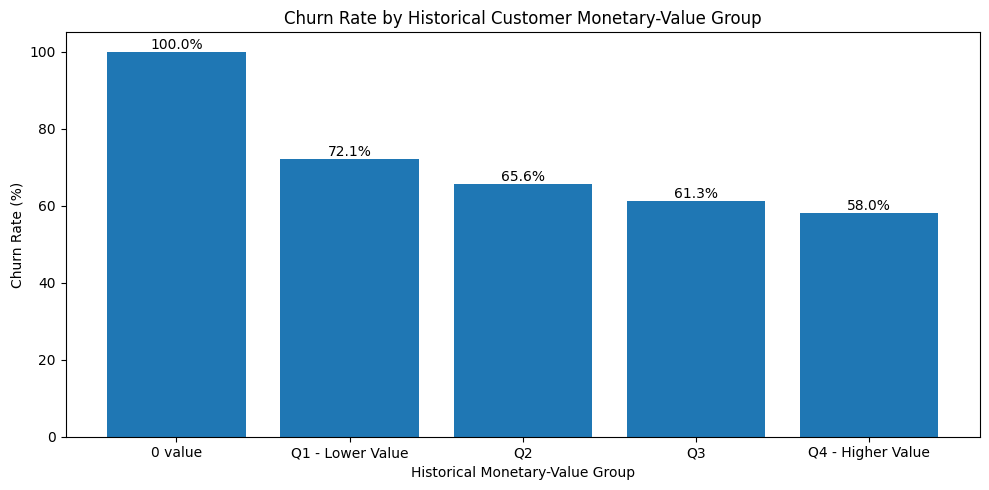


--- VALIDATION ---
Monetary-group population reconciliation: PASS
Churned-customer reconciliation: PASS
Active-customer reconciliation: PASS
Churn rates within valid range: PASS

Cell 33: Monetary-Value Churn Analysis COMPLETE.


In [ ]:
# ============================================================
# CELL 33 — CHURN RATE BY CUSTOMER MONETARY-VALUE GROUP
# ============================================================
# Purpose:
# Examine whether churn status differs across levels of
# historical customer monetary value.
#
# Method:
# - Customers with monetary_total = 0 are kept as a separate
#   group because they have no qualifying completed-order value.
# - Customers with monetary_total > 0 are divided into
#   quartile groups (Q1–Q4).
#
# Important:
# This is descriptive analysis. It does NOT establish that
# higher or lower spending causes churn.
# ============================================================

# ------------------------------------------------------------
# 1. Prepare analysis dataset
# ------------------------------------------------------------

monetary_churn = customers_rfm[
    [
        "customer_id",
        "monetary_total",
        "churn_status",
        "churn_flag"
    ]
].copy()

# ------------------------------------------------------------
# 2. Separate zero-value customers
# ------------------------------------------------------------

zero_value_mask = (
    monetary_churn["monetary_total"] == 0
)

monetary_churn["monetary_group"] = "0 value"

# ------------------------------------------------------------
# 3. Create quartiles among positive-value customers
# ------------------------------------------------------------

positive_value = monetary_churn.loc[
    ~zero_value_mask,
    "monetary_total"
]

monetary_churn.loc[
    ~zero_value_mask,
    "monetary_group"
] = pd.qcut(
    positive_value,
    q=4,
    labels=[
        "Q1 - Lower Value",
        "Q2",
        "Q3",
        "Q4 - Higher Value"
    ],
    duplicates="drop"
)

# ------------------------------------------------------------
# 4. Define logical order
# ------------------------------------------------------------

monetary_order = [
    "0 value",
    "Q1 - Lower Value",
    "Q2",
    "Q3",
    "Q4 - Higher Value"
]

monetary_churn["monetary_group"] = pd.Categorical(
    monetary_churn["monetary_group"],
    categories=monetary_order,
    ordered=True
)

# ------------------------------------------------------------
# 5. Calculate group boundaries for positive-value customers
# ------------------------------------------------------------

monetary_quartiles = (
    positive_value
    .quantile([0.25, 0.50, 0.75])
)

print("CUSTOMER MONETARY-VALUE QUARTILES")
print("=" * 60)

print(
    f"Q1 boundary: ${monetary_quartiles.loc[0.25]:,.2f}"
)

print(
    f"Median boundary: ${monetary_quartiles.loc[0.50]:,.2f}"
)

print(
    f"Q3 boundary: ${monetary_quartiles.loc[0.75]:,.2f}"
)

# ------------------------------------------------------------
# 6. Calculate churn statistics
# ------------------------------------------------------------

monetary_churn_summary = (
    monetary_churn
    .groupby(
        "monetary_group",
        observed=False
    )
    .agg(
        customers=("customer_id", "count"),
        active_customers=(
            "churn_status",
            lambda x: (x == "Active").sum()
        ),
        churned_customers=(
            "churn_status",
            lambda x: (x == "Churned").sum()
        ),
        churn_rate=("churn_flag", "mean")
    )
    .reset_index()
)

monetary_churn_summary["churn_rate_pct"] = (
    monetary_churn_summary["churn_rate"] * 100
)

# ------------------------------------------------------------
# 7. Print results
# ------------------------------------------------------------

print("\nCHURN RATE BY MONETARY-VALUE GROUP")
print("=" * 65)

print(
    monetary_churn_summary[
        [
            "monetary_group",
            "customers",
            "active_customers",
            "churned_customers",
            "churn_rate_pct"
        ]
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 8. Visualise churn rate
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

bars = plt.bar(
    monetary_churn_summary["monetary_group"].astype(str),
    monetary_churn_summary["churn_rate_pct"]
)

plt.title(
    "Churn Rate by Historical Customer Monetary-Value Group"
)

plt.xlabel("Historical Monetary-Value Group")
plt.ylabel("Churn Rate (%)")

for bar, rate in zip(
    bars,
    monetary_churn_summary["churn_rate_pct"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{rate:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Validation
# ------------------------------------------------------------

assert (
    monetary_churn_summary["customers"].sum()
    == len(customers_rfm)
), "Monetary-group population does not reconcile."

assert (
    monetary_churn_summary["churned_customers"].sum()
    == (customers_rfm["churn_status"] == "Churned").sum()
), "Churned-customer count does not reconcile."

assert (
    monetary_churn_summary["active_customers"].sum()
    == (customers_rfm["churn_status"] == "Active").sum()
), "Active-customer count does not reconcile."

assert (
    monetary_churn_summary["churn_rate_pct"].between(0, 100).all()
), "Invalid churn-rate percentage detected."

print("\n--- VALIDATION ---")

print(
    "Monetary-group population reconciliation: PASS"
    if monetary_churn_summary["customers"].sum()
    == len(customers_rfm)
    else "Monetary-group population reconciliation: FAIL"
)

print(
    "Churned-customer reconciliation: PASS"
    if monetary_churn_summary["churned_customers"].sum()
    == (customers_rfm["churn_status"] == "Churned").sum()
    else "Churned-customer reconciliation: FAIL"
)

print(
    "Active-customer reconciliation: PASS"
    if monetary_churn_summary["active_customers"].sum()
    == (customers_rfm["churn_status"] == "Active").sum()
    else "Active-customer reconciliation: FAIL"
)

print(
    "Churn rates within valid range: PASS"
    if monetary_churn_summary["churn_rate_pct"].between(0, 100).all()
    else "Churn rates within valid range: FAIL"
)

print(
    "\nCell 33: Monetary-Value Churn Analysis COMPLETE."
)

# Chart Insights & Business Interpretation

### Chart 19 — Churn rate by historical customer monetary-value group

Churn decreases from **72.08% in the lower-value positive-spend group to 57.97% in the highest-value group**, while all 447 zero-value customers are churned under the project definition. Higher-value customers therefore appear somewhat more retained, but the 57.97% churn rate in the top value group shows that high historical value does not make customers immune to churn.



In [ ]:
# ============================================================
# CELL 34 — FINAL EDA KPI & FINDINGS SUMMARY
# ============================================================
# Purpose:
# Consolidate the major validated EDA findings into one
# reusable summary table.
#
# This table will support:
# - Final EDA reporting
# - Presentation slides
# - README
# - Business recommendations
# - Viva preparation
#
# IMPORTANT:
# These are descriptive findings. They do not establish
# causation.
# ============================================================

# ------------------------------------------------------------
# 1. Core churn metrics
# ------------------------------------------------------------

total_customers = len(customers_rfm)

active_count = (
    customers_rfm["churn_status"] == "Active"
).sum()

churned_count = (
    customers_rfm["churn_status"] == "Churned"
).sum()

overall_churn_rate = (
    churned_count / total_customers * 100
)

# ------------------------------------------------------------
# 2. RFM metrics
# ------------------------------------------------------------

active_customers_rfm = customers_rfm[
    customers_rfm["churn_status"] == "Active"
]

churned_customers_rfm = customers_rfm[
    customers_rfm["churn_status"] == "Churned"
]

active_recency_median = (
    active_customers_rfm["recency_days"].median()
)

churned_recency_median = (
    churned_customers_rfm["recency_days"].median()
)

active_frequency_median = (
    active_customers_rfm["frequency"].median()
)

churned_frequency_median = (
    churned_customers_rfm["frequency"].median()
)

active_monetary_median = (
    active_customers_rfm["monetary_total"].median()
)

churned_monetary_median = (
    churned_customers_rfm["monetary_total"].median()
)

# ------------------------------------------------------------
# 3. Support metrics
# ------------------------------------------------------------

support_customer_level = (
    support_tickets
    .groupby("customer_id")
    .agg(
        average_resolution_hours=(
            "resolution_time_hours",
            "mean"
        )
    )
)

support_customer_level = support_customer_level.merge(
    customers_rfm[
        ["customer_id", "churn_status"]
    ],
    left_index=True,
    right_on="customer_id",
    how="left"
)

active_support_median = (
    support_customer_level.loc[
        support_customer_level["churn_status"] == "Active",
        "average_resolution_hours"
    ].median()
)

churned_support_median = (
    support_customer_level.loc[
        support_customer_level["churn_status"] == "Churned",
        "average_resolution_hours"
    ].median()
)

# ------------------------------------------------------------
# 4. Historical value metrics
# ------------------------------------------------------------

historical_value_by_status = (
    customers_rfm
    .groupby("churn_status")["monetary_total"]
    .sum()
)

total_historical_value = (
    historical_value_by_status.sum()
)

churned_historical_value = (
    historical_value_by_status["Churned"]
)

churned_value_share = (
    churned_historical_value
    / total_historical_value
    * 100
)

# ------------------------------------------------------------
# 5. Purchase-frequency relationship
# ------------------------------------------------------------

frequency_monetary_spearman = (
    customers_rfm[
        ["frequency", "monetary_total"]
    ]
    .corr(method="spearman")
    .iloc[0, 1]
)

# ------------------------------------------------------------
# 6. Create consolidated findings table
# ------------------------------------------------------------

eda_findings = pd.DataFrame({
    "Finding": [
        "Overall churn rate",
        "Churned customers",
        "Active customers",
        "Median recency — Active",
        "Median recency — Churned",
        "Median frequency — Active",
        "Median frequency — Churned",
        "Median monetary value — Active",
        "Median monetary value — Churned",
        "Median support resolution — Active",
        "Median support resolution — Churned",
        "Churned customers' share of historical value",
        "Frequency–monetary Spearman correlation"
    ],

    "Value": [
        overall_churn_rate,
        churned_count,
        active_count,
        active_recency_median,
        churned_recency_median,
        active_frequency_median,
        churned_frequency_median,
        active_monetary_median,
        churned_monetary_median,
        active_support_median,
        churned_support_median,
        churned_value_share,
        frequency_monetary_spearman
    ],

    "Unit": [
        "%",
        "customers",
        "customers",
        "days",
        "days",
        "orders",
        "orders",
        "currency",
        "currency",
        "hours",
        "hours",
        "%",
        "correlation"
    ]
})

# ------------------------------------------------------------
# 7. Display consolidated findings
# ------------------------------------------------------------

print("FINAL EDA KPI & FINDINGS SUMMARY")
print("=" * 70)

print(
    eda_findings.to_string(index=False)
)

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

assert active_count + churned_count == total_customers, \
    "Active and churned counts do not reconcile."

assert 0 <= overall_churn_rate <= 100, \
    "Invalid overall churn rate."

assert churned_historical_value >= 0, \
    "Negative churned historical value detected."

assert 0 <= churned_value_share <= 100, \
    "Invalid historical-value share."

assert -1 <= frequency_monetary_spearman <= 1, \
    "Invalid Spearman correlation."

assert active_support_median >= 0, \
    "Invalid active support resolution median."

assert churned_support_median >= 0, \
    "Invalid churned support resolution median."

print("\n--- VALIDATION ---")

print(
    "Active + Churned = Total customers: PASS"
    if active_count + churned_count == total_customers
    else "Active + Churned = Total customers: FAIL"
)

print(
    "Overall churn rate valid: PASS"
    if 0 <= overall_churn_rate <= 100
    else "Overall churn rate valid: FAIL"
)

print(
    "Historical-value share valid: PASS"
    if 0 <= churned_value_share <= 100
    else "Historical-value share valid: FAIL"
)

print(
    "Spearman correlation valid: PASS"
    if -1 <= frequency_monetary_spearman <= 1
    else "Spearman correlation valid: FAIL"
)

print(
    "\nCell 34: Final EDA KPI & Findings Summary COMPLETE."
)

FINAL EDA KPI & FINDINGS SUMMARY
                                     Finding       Value        Unit
                          Overall churn rate   66.863711           %
                           Churned customers 4072.000000   customers
                            Active customers 2018.000000   customers
                     Median recency — Active   87.000000        days
                    Median recency — Churned  454.000000        days
                   Median frequency — Active    5.000000      orders
                  Median frequency — Churned    4.000000      orders
              Median monetary value — Active 6981.655000    currency
             Median monetary value — Churned 5426.335000    currency
          Median support resolution — Active   12.400000       hours
         Median support resolution — Churned   14.125000       hours
Churned customers' share of historical value   61.172563           %
     Frequency–monetary Spearman correlation    0.810999 correlation

